# PayTrust AI: would you approve the launch?
### A hands-on AI governance case study

Imagine you are the Chief AI Governance Officer at PayTrust AI, a digital payments company in Pakistan. The product team is excited because their new fraud model scores 96% accuracy, and they want to go live next week.

Before you sign anything, a few complaints have reached your desk. Some genuine customers can't complete their payments. Loan approvals look quite different from one customer group to another. And several safeguards the team promised are still unfinished.

Your job is to look past the headline number, work through the evidence, and decide whether PayTrust should launch.

My starting position: we should not approve an unrestricted live launch. The team can keep testing offline, or in shadow mode where the model scores payments but never acts on them, as long as customer data stays protected.

> **A note on the data.** Every number here is made up for teaching. The original case only gives us "96% accuracy", with no confusion matrix, group breakdown or audit. So we simulate six months of payments and train the model the way the team describes, and every section of the notebook uses that same data and model. It says nothing about any real payment company.

**What you'll practise:** reading a confusion matrix, fraud precision and recall, putting a price on mistakes, checking fairness between groups, and using NIST AI RMF, the EU AI Act, the OECD AI Principles and Pakistan's National AI Policy to reach a decision you can defend.

**Parts 1 to 8** ask whether the system is ready. **Parts 9 to 15** go further and show how to actually apply the four NIST functions (Govern, Map, Measure, Manage) to a working fraud model, then compare the system before and after and record the CTO's decision.

Run the cells from top to bottom in Google Colab. The free CPU runtime is fine, and you don't need an API key or any external data.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from IPython.display import display, Markdown
rng = np.random.default_rng(42)
print('All set. The data in this notebook is synthetic, and every run gives the same results.')

All set. The data in this notebook is synthetic, and every run gives the same results.


## Before we start: the payments and the model the team built

Every number in this notebook comes from one simulated dataset and one model, so nothing changes between sections. This short setup creates both.

**The payments.** We simulate six months of transactions, 12,000 a month. Each one records the amount, time of day, whether the device is new, distance from the customer's usual location, how many payments they've made in the last hour, how risky the merchant is, and any failed PIN attempts.

We also note which of two customer segments each person belongs to: **Established** customers, or **New-to-digital** customers who have only recently started using mobile wallets. This isn't a protected characteristic like gender or religion, but it matters a great deal for financial inclusion. If the model keeps blocking people who are new to digital payments, it pushes them back out of the system. That's exactly what Pakistan's National AI Policy and the OECD fairness principle ask us to watch for.

The months are used like this:
- months 1 to 3 to train the model;
- month 4 to tune it;
- month 5 as the test month, which the model never sees during development. **Parts 1 to 8 look at this month;**
- month 6 as a "future" month where things change. A big onboarding campaign brings in lots of new customers, and a fraud ring starts targeting newly registered devices. We use it later, in Part 12.

**The team's model.** This is a common way models end up in production:
- every available column goes in, including the customer segment and account age;
- fraud cases get extra weight during training, and the cut-off is chosen to keep accuracy at 96% or above on month 4 while catching as much fraud as possible, because 96% was the number everyone wanted to see;
- anything the model flags is blocked automatically. Nobody reviews it, the customer gets no explanation and there's no way to appeal.

You don't need to follow every line of the next two cells to do Parts 1 to 8. Just run them.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, brier_score_loss
import hashlib, json, datetime

def make_transactions(n, month, rng, drift=False):
    seg_new = rng.random(n) < (0.55 if drift else 0.30)          # month 6: big onboarding campaign
    amount = np.exp(rng.normal(7.6, 1.0, n))                       # PKR, typical payment around 2,000
    hour = rng.integers(0, 24, n)
    new_device = rng.random(n) < np.where(seg_new, 0.22, 0.05)
    distance = np.exp(rng.normal(np.where(seg_new, 3.0, 2.0), 0.9, n))
    velocity = rng.poisson(np.where(seg_new, 1.4, 1.0))
    acct_age = np.where(seg_new, rng.integers(5, 180, n), rng.integers(90, 3000, n))
    merchant_risk = rng.beta(2, 8, n)
    failed_pin = rng.poisson(0.1, n)
    night = (hour <= 4).astype(int)

    # How fraud really happens in our simulation. Account age and segment play no direct part.

    z = (-13.4 + 1.1*(np.log(amount)-7.6) + 3.8*new_device + 0.3*np.log1p(distance)
         + 1.5*velocity + 12.0*merchant_risk + 2.4*failed_pin + 2.2*night)
    if drift: z = z + 0.6 + 1.2*new_device                          # month 6: a fraud ring goes after new devices
    fraud = rng.random(n) < 1/(1+np.exp(-z))
    return pd.DataFrame(dict(month=month, segment=np.where(seg_new,'New-to-digital','Established'),
        amount_pkr=amount.round(0), hour=hour, new_device=new_device.astype(int), distance_km=distance.round(1),
        txn_velocity_1h=velocity, account_age_days=acct_age, merchant_risk=merchant_risk.round(3),
        failed_pin=failed_pin, is_fraud=fraud.astype(int)))

sim_rng = np.random.default_rng(2026)
txns = pd.concat([make_transactions(12000, m, sim_rng, drift=(m == 6)) for m in range(1, 7)], ignore_index=True)
txns['segment_flag'] = (txns.segment == 'New-to-digital').astype(int)
txns.insert(0, 'txn_id', [f'T{i:06d}' for i in range(len(txns))])
txns['week'] = (txns.groupby('month').cumcount() // 3000) + 1 + (txns.month - 1) * 4   # four weeks in each month

train, valid, test, future = (txns[txns.month <= 3], txns[txns.month == 4], txns[txns.month == 5], txns[txns.month == 6])
SEGMENTS = ['Established', 'New-to-digital']
display(txns.groupby('month').agg(transactions=('txn_id','size'), fraud_rate=('is_fraud','mean'),
                                  new_to_digital_share=('segment_flag','mean')).round(4))
display(txns.head(3))

,transactions,fraud_rate,new_to_digital_share
month,,,
1,12000,0.0276,0.2962
2,12000,0.0252,0.3078
3,12000,0.0234,0.2975
4,12000,0.0241,0.3032
5,12000,0.0232,0.2950
6,12000,0.0580,0.5461


,txn_id,month,segment,amount_pkr,hour,new_device,distance_km,txn_velocity_1h,account_age_days,merchant_risk,failed_pin,is_fraud,segment_flag,week
0,T000000,1,New-to-digital,3032.0,6,1,12.0,0,166,0.244,0,0,1,1
1,T000001,1,Established,1035.0,13,0,12.7,1,278,0.205,0,0,0,1
2,T000002,1,Established,1629.0,1,0,7.0,3,1410,0.088,0,0,0,1


In [ ]:
def outcome_metrics(y, blocked, seg, label, extra_cost=0.0):
    # What the customer actually experiences: 'blocked' means the payment did not go through.
    # The costs per mistake (COST_FALSE_BLOCK, COST_MISSED_FRAUD) are set in Part 2.
    y, blocked, seg = np.asarray(y), np.asarray(blocked).astype(bool), np.asarray(seg)
    tp = int((blocked & (y==1)).sum()); fp = int((blocked & (y==0)).sum())
    fn = int((~blocked & (y==1)).sum()); tn = int((~blocked & (y==0)).sum())
    seg_fpr = {s: ((blocked & (y==0) & (seg==s)).sum() / max(((y==0) & (seg==s)).sum(), 1)) for s in SEGMENTS}
    return {'System': label, 'Accuracy': (tp+tn)/len(y), 'Fraud recall': tp/max(tp+fn,1),
            'Precision of blocks': tp/max(tp+fp,1), 'False-positive rate': fp/max(fp+tn,1),
            'Legit payments blocked': fp, 'Fraud missed': fn,
            'FPR Established': seg_fpr['Established'], 'FPR New-to-digital': seg_fpr['New-to-digital'],
            'Segment FPR gap (pp)': 100*abs(seg_fpr['New-to-digital'] - seg_fpr['Established']),
            'Total cost (PKR)': fp*COST_FALSE_BLOCK + fn*COST_MISSED_FRAUD + extra_cost}

FEATURES_ALL = ['amount_pkr','hour','new_device','distance_km','txn_velocity_1h','account_age_days',
                'merchant_risk','failed_pin','segment_flag']
baseline = HistGradientBoostingClassifier(class_weight='balanced', max_iter=200, random_state=0)
baseline.fit(train[FEATURES_ALL], train.is_fraud)

# The team picks the cut-off on month 4: keep accuracy at 96% or more and catch as much fraud as possible
val_scores = baseline.predict_proba(valid[FEATURES_ALL])[:, 1]
cands = []
for t in np.arange(0.50, 0.99, 0.01):
    b = val_scores >= t
    acc = ((b & (valid.is_fraud==1)) | (~b & (valid.is_fraud==0))).mean()
    rec = (b & (valid.is_fraud==1)).sum() / valid.is_fraud.sum()
    if acc >= 0.96: cands.append((rec, -t, t, acc))
_, _, baseline_threshold, team_headline_accuracy = max(cands)

# The model's decisions on the test month. Parts 1 to 8 all analyse exactly these decisions.
test_scores_before = baseline.predict_proba(test[FEATURES_ALL])[:, 1]
blocked_before = test_scores_before >= baseline_threshold
print(f"The team's headline: {team_headline_accuracy:.1%} accuracy on month 4, using a cut-off of {baseline_threshold:.2f}.")
print(f'The model has now made its decisions on the {len(test):,} payments in month 5. Part 1 looks at them.')

The team's headline: 96.0% accuracy on month 4, using a cut-off of 0.77.
The model has now made its decisions on the 12,000 payments in month 5. Part 1 looks at them.


## Part 1: Take a closer look at "96% accuracy"

The team's model scored 96% on the month it was tuned on. The fair test is month 5, which the model has never seen. The next cell counts what it got right and wrong there, and sets the results out in a confusion matrix:

| | Model says legitimate | Model says fraud |
|---|---|---|
| Actually legitimate | True negative (TN): correctly allowed | False positive (FP): genuine payment blocked |
| Actually fraud | False negative (FN): fraud let through | True positive (TP): fraud stopped |

In month 5 there were **12,000 payments**, and **279** of them were fraud.
The model got **11,551** right and **449** wrong, which is **96.3% accuracy**.

Now look at *which* ones it got wrong. It stopped **386 genuine payments** and let **63 fraudulent ones** through.

| | Model says legitimate | Model says fraud |
|---|---:|---:|
| Actually legitimate | 11,335 (TN) | 386 (FP) |
| Actually fraud | 63 (FN) | 216 (TP) |

Here's the uncomfortable part. A "model" that simply approves everything would score
**97.7% accuracy** on this month, higher than ours, and catch no fraud at all.
So the accuracy figure on its own tells us very little.

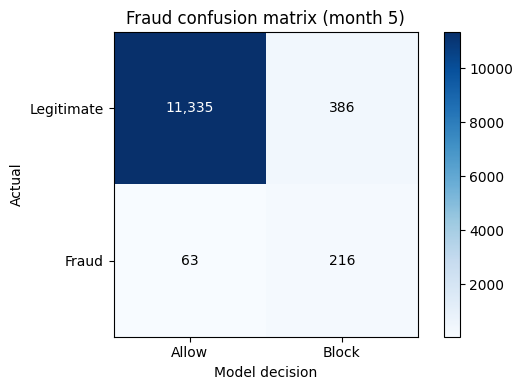

In [ ]:
y_true = test.is_fraud.values
y_pred = blocked_before.astype(int)
cm = confusion_matrix(y_true, y_pred, labels=[0, 1]); tn, fp, fn, tp = (int(v) for v in cm.ravel())
n_payments, n_fraud = len(y_true), int(y_true.sum())

display(Markdown(f'''In month 5 there were **{n_payments:,} payments**, and **{n_fraud:,}** of them were fraud.
The model got **{tp + tn:,}** right and **{fp + fn:,}** wrong, which is **{(tp + tn) / n_payments:.1%} accuracy**.

Now look at *which* ones it got wrong. It stopped **{fp:,} genuine payments** and let **{fn:,} fraudulent ones** through.

| | Model says legitimate | Model says fraud |
|---|---:|---:|
| Actually legitimate | {tn:,} (TN) | {fp:,} (FP) |
| Actually fraud | {fn:,} (FN) | {tp:,} (TP) |

Here's the uncomfortable part. A "model" that simply approves everything would score
**{1 - n_fraud / n_payments:.1%} accuracy** on this month, higher than ours, and catch no fraud at all.
So the accuracy figure on its own tells us very little.'''))

fig, ax = plt.subplots(figsize=(6, 4)); im = ax.imshow(cm, cmap='Blues')
ax.set_xticks([0, 1], ['Allow', 'Block']); ax.set_yticks([0, 1], ['Legitimate', 'Fraud'])
ax.set_xlabel('Model decision'); ax.set_ylabel('Actual'); ax.set_title('Fraud confusion matrix (month 5)')
for (i, j), v in np.ndenumerate(cm): ax.text(j, i, f'{v:,}', ha='center', va='center', color='white' if v > cm.max() / 2 else 'black')
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

Before you run the next cell, try working these out from the matrix yourself:

- Accuracy = (TP + TN) / all payments
- Fraud precision = TP / (TP + FP). Of the payments we blocked, how many were really fraud?
- Fraud recall = TP / (TP + FN). How much of the fraud did we catch?
- False-positive rate = FP / (FP + TN). What share of genuine payments did we block?

In [ ]:
metrics = {'Accuracy': accuracy_score(y_true, y_pred), 'Precision (fraud)': precision_score(y_true, y_pred),
           'Recall (fraud)': recall_score(y_true, y_pred), 'F1 (fraud)': f1_score(y_true, y_pred),
           'False positive rate': fp / (fp + tn), 'False negative rate': fn / (fn + tp), 'False discovery rate': fp / (fp + tp)}
display(pd.DataFrame({'Metric': list(metrics), 'Value': list(metrics.values())}).round(4))

,Metric,Value
0,Accuracy,0.9626
1,Precision (fraud),0.3588
2,Recall (fraud),0.7742
3,F1 (fraud),0.4904
4,False positive rate,0.0329
5,False negative rate,0.2258
6,False discovery rate,0.6412


### Something to think about

Only about 2 in every 100 payments here are fraud. A model that waves every transaction through looks *more* accurate than ours, yet it misses every single fraud case. That's why a governance review never stops at one metric. We need several measures, and we need to know what each kind of mistake costs.

In [ ]:
fraud_prevalence = (tp + fn) / (tp + tn + fp + fn)  # share of all payments that really are fraud

naive_accuracy = 1 - fraud_prevalence            # a lazy 'model' that approves everything

comparison = pd.DataFrame({
    'Approach': ['PayTrust example', 'Always predict legitimate'],
    'Accuracy': [metrics['Accuracy'], naive_accuracy],
    'Fraud recall': [metrics['Recall (fraud)'], 0.0],
    'Legitimate payments blocked': [int(fp), 0],
    'Fraudulent payments missed': [int(fn), int(tp + fn)]
})
display(comparison)
print('Takeaway: accuracy alone tells you very little about whether a fraud system is useful or fair.')

,Approach,Accuracy,Fraud recall,Legitimate payments blocked,Fraudulent payments missed
0,PayTrust example,0.962583,0.774194,386,63
1,Always predict legitimate,0.976750,0.000000,0,279


Takeaway: accuracy alone tells you very little about whether a fraud system is useful or fair.


## Part 2: What does a mistake cost?

Consider someone at a pharmacy counter whose card is declined even though nothing is wrong. Support may sort it out later, but by then they've been embarrassed, maybe left without their medicine, maybe out of pocket. A missed fraud hurts in a different way: someone loses money they may never get back.

To make the trade-off concrete, we'll assume a wrongly blocked payment costs PKR 1,500 and a missed fraud costs PKR 20,000. These figures are invented for the exercise. In a real review the finance, fraud and customer teams would supply measured losses, refund obligations and a sensible range of uncertainty.

,Error,Count,Unit cost (PKR),Estimated cost (PKR)
0,Legitimate payment blocked,386,1500,579000
1,Fraud not detected,63,20000,1260000


Estimated total cost of mistakes (illustrative): PKR 1,839,000


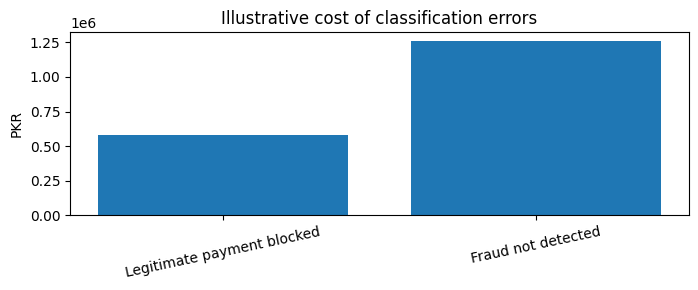

In [ ]:
false_block_cost=1500; missed_fraud_cost=20000
COST_FALSE_BLOCK, COST_MISSED_FRAUD = false_block_cost, missed_fraud_cost   # used again in Parts 9 to 15
cost_fp=fp*false_block_cost; cost_fn=fn*missed_fraud_cost
costs=pd.DataFrame({'Error':['Legitimate payment blocked','Fraud not detected'],'Count':[fp,fn],'Unit cost (PKR)':[false_block_cost,missed_fraud_cost],'Estimated cost (PKR)':[cost_fp,cost_fn]})
display(costs); print(f'Estimated total cost of mistakes (illustrative): PKR {cost_fp+cost_fn:,}')
fig,ax=plt.subplots(figsize=(7,3));ax.bar(costs['Error'],costs['Estimated cost (PKR)']);ax.set_ylabel('PKR');ax.set_title('Illustrative cost of classification errors');plt.xticks(rotation=12);plt.tight_layout();plt.show()

## Part 3: The loan approval model

PayTrust also uses AI to decide on loans. We compare two anonymised groups of 1,000 applicants each. Group A gets 700 approvals; Group B gets 450.

A 25 percentage point gap like that needs investigating, but it doesn't prove unlawful discrimination by itself. The groups might genuinely differ in credit history, income or data quality, and the sample is small.

We also include a simple count of "qualified" applicants in each group, which gives a second angle. Keep in mind that the qualification rule itself would need independent checking and legal review. The group labels are deliberately generic. A real audit would need properly and lawfully collected group data, with privacy protections in place.

,group,applicants,approved,qualified_applicants,qualified_approved,approval_rate,qualified_approval_rate
0,Group A,1000,700,600,540,0.70,0.90
1,Group B,1000,450,600,390,0.45,0.65


Approval rate gap: 25.0%; selection-rate ratio: 0.643; qualified approval gap: 25.0%
Note: the 80% rule of thumb is a quick screening check. Passing or failing it does not settle the legal question.


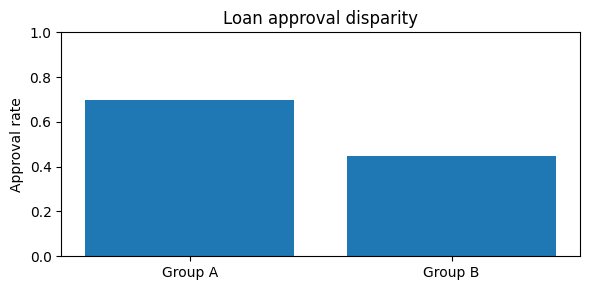

In [ ]:
loans=pd.DataFrame({'group':['Group A','Group B'],'applicants':[1000,1000],'approved':[700,450],'qualified_applicants':[600,600],'qualified_approved':[540,390]})
loans['approval_rate']=loans.approved/loans.applicants
loans['qualified_approval_rate']=loans.qualified_approved/loans.qualified_applicants
rate_gap=loans.approval_rate.max()-loans.approval_rate.min()
selection_ratio=loans.approval_rate.min()/loans.approval_rate.max()
qualified_gap=loans.qualified_approval_rate.max()-loans.qualified_approval_rate.min()
display(loans)
print(f'Approval rate gap: {rate_gap:.1%}; selection-rate ratio: {selection_ratio:.3f}; qualified approval gap: {qualified_gap:.1%}')
print('Note: the 80% rule of thumb is a quick screening check. Passing or failing it does not settle the legal question.')
fig,ax=plt.subplots(figsize=(6,3));ax.bar(loans.group,loans.approval_rate);ax.set_ylim(0,1);ax.set_ylabel('Approval rate');ax.set_title('Loan approval disparity');plt.tight_layout();plt.show()

## Part 4: Use NIST AI RMF like an investigator

The NIST AI Risk Management Framework is built around four functions: Govern, Map, Measure and Manage. It's a voluntary framework for managing risk. It isn't a certification and it doesn't hand out pass marks.

For discussion, we give PayTrust a rough maturity score out of 5 for each function. NIST does not define these numbers, so treat them as a way of organising your questions:

- **Govern:** Who owns the model? Who has the authority to switch it off? Are there written policies and an audit trail?
- **Map:** Which customers, payment situations and credit decisions could be affected, and how?
- **Measure:** Have we checked errors for each customer group, false blocks, calibration, drift and uncertainty?
- **Manage:** Can customers appeal? Can staff overrule the model? Can we roll it back quickly?

A weak answer to any one of these can be reason enough to delay a launch, however good the headline metric looks.

,Function,Evidence expected,Illustrative maturity / 5,Required remediation
0,GOVERN,"Roles, accountability, policies, documented ap...",1,Assign accountable owner; complete policies an...
1,MAP,"Intended use, impacted groups, downstream harms",2,"Document risk register, stakeholder impact and..."
2,MEASURE,"Fraud error costs, group fairness, robustness,...",2,Validate on representative held-out data and s...
3,MANAGE,"Appeals, monitoring, rollback, incident response",1,"Implement human review, appeal, rollback and i..."


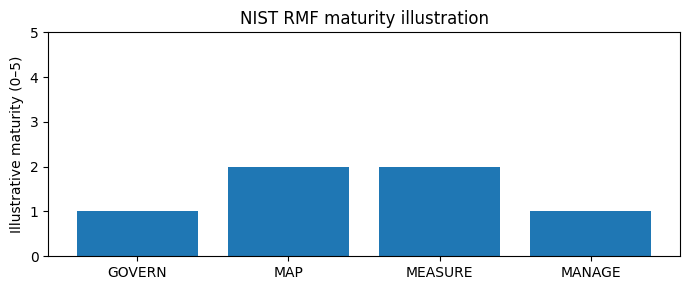

In [ ]:
nist=pd.DataFrame([
('GOVERN','Roles, accountability, policies, documented approvals',1,'Assign accountable owner; complete policies and independent review'),
('MAP','Intended use, impacted groups, downstream harms',2,'Document risk register, stakeholder impact and system boundaries'),
('MEASURE','Fraud error costs, group fairness, robustness, calibration',2,'Validate on representative held-out data and subgroups'),
('MANAGE','Appeals, monitoring, rollback, incident response',1,'Implement human review, appeal, rollback and incident plan')],columns=['Function','Evidence expected','Illustrative maturity / 5','Required remediation'])
display(nist)
fig,ax=plt.subplots(figsize=(7,3));ax.bar(nist.Function,nist['Illustrative maturity / 5']);ax.set_ylim(0,5);ax.set_ylabel('Illustrative maturity (0–5)');ax.set_title('NIST RMF maturity illustration');plt.tight_layout();plt.show()

## Part 5: Four frameworks, one decision

**NIST AI RMF.** Name the owners, the people affected, the risks you can measure and the controls you'll use. Look at all four functions together instead of averaging them into one score.

**EU AI Act.** Be precise about what each system does. AI that assesses a person's creditworthiness or sets their credit score is generally listed as high-risk in Annex III, point 5(b). That same entry carves out AI used to detect financial fraud. The carve-out doesn't mean a fraud system has no obligations at all. Whether the Act applies, from which dates, and in what role PayTrust would be acting are all questions for a lawyer. A service offered only in Pakistan isn't automatically covered.

**OECD AI Principles.** Is PayTrust treating people fairly and respecting their rights? Can it explain important decisions? Is the system reliable and secure? Is someone clearly accountable?

**Pakistan's National AI Policy.** Responsible innovation, inclusion, skills and public trust are useful goals to align with. A policy is not a law, though. A real launch would also need legal advice on Pakistan's financial, consumer protection, data protection and regulator-specific rules.

The table below is a guide for discussion, not a legal compliance certificate.

In [ ]:
framework=pd.DataFrame([
('NIST AI RMF','GOVERN','Incomplete accountability and controls','Appoint owners, audit and document risk acceptance'),
('NIST AI RMF','MAP','Customer payment and credit harms','Map affected populations and contexts'),
('NIST AI RMF','MEASURE','96% accuracy masks false positives and group disparities','Measure FPR, recall, costs, fairness and uncertainty'),
('NIST AI RMF','MANAGE','No demonstrated mitigation and appeals','Human review, incident response, monitoring and rollback'),
('EU AI Act','Annex III 5(b)','Natural-person creditworthiness model potentially high-risk','Conduct legal classification and required high-risk compliance assessment'),
('EU AI Act','Fraud detection exception','Financial fraud detection excluded from Annex III 5(b) entry','Classify fraud module separately; assess other applicable duties'),
('OECD AI Principles','Fairness, transparency, robustness, accountability','Disparate impact and weak oversight','Test impacts, explain decisions, create contestability and audit trail'),
('Pakistan National AI Policy 2025','Responsible, inclusive and trustworthy AI','Risk to financial inclusion and customer trust','Align governance with policy; review applicable SBP and Pakistani laws')],columns=['Framework','Area','Finding','Action'])
display(framework)

,Framework,Area,Finding,Action
0,NIST AI RMF,GOVERN,Incomplete accountability and controls,"Appoint owners, audit and document risk accept..."
1,NIST AI RMF,MAP,Customer payment and credit harms,Map affected populations and contexts
2,NIST AI RMF,MEASURE,96% accuracy masks false positives and group d...,"Measure FPR, recall, costs, fairness and uncer..."
3,NIST AI RMF,MANAGE,No demonstrated mitigation and appeals,"Human review, incident response, monitoring an..."
4,EU AI Act,Annex III 5(b),Natural-person creditworthiness model potentia...,Conduct legal classification and required high...
5,EU AI Act,Fraud detection exception,Financial fraud detection excluded from Annex ...,Classify fraud module separately; assess other...
6,OECD AI Principles,"Fairness, transparency, robustness, accountabi...",Disparate impact and weak oversight,"Test impacts, explain decisions, create contes..."
7,Pakistan National AI Policy 2025,"Responsible, inclusive and trustworthy AI",Risk to financial inclusion and customer trust,Align governance with policy; review applicabl...


## Part 6: Set the bar before you look at the results

We'll test the system against some internal thresholds, which we write down now so nobody is tempted to adjust them later:

- no more than 1% of genuine payments blocked;
- no more than a 10 percentage point gap in loan approval rates, until a deeper fairness review is done;
- a maturity score of at least 3 out of 5 on every NIST function;
- a working appeals process, human review, incident response plan and independent audit.

To be clear, none of these numbers comes from NIST, the EU AI Act, the OECD or Pakistan's policy. They're our own choices for this exercise. A real organisation would set them from its risk appetite, the law and proper validation.

__________________________________________________________________________

A question to discuss: if the team brought the false-positive rate down but appeals and incident response still didn't exist, would you let them launch?

__________________________________________________________________________

In [ ]:
limits={'max_fpr':0.01,'max_approval_gap':0.10,'min_nist_maturity':3}
controls={'appeal_process':False,'human_review':False,'incident_response':False,'independent_audit':False}
checks=pd.DataFrame([
('Fraud false-positive rate',metrics['False positive rate']<=limits['max_fpr'],f"Observed {metrics['False positive rate']:.2%}; gate <= 1%"),
('Loan approval-rate gap',rate_gap<=limits['max_approval_gap'],f'Observed {rate_gap:.1%}; gate <= 10 pp'),
('NIST maturity minimum',bool((nist['Illustrative maturity / 5']>=limits['min_nist_maturity']).all()),'All functions must score >= 3'),
('Customer appeal process',controls['appeal_process'],'Documented, tested and staffed'),
('Human review',controls['human_review'],'Meaningful human override for adverse decisions'),
('Incident response',controls['incident_response'],'Tested escalation, monitoring and rollback'),
('Independent audit',controls['independent_audit'],'Evidence-based validation and sign-off')],columns=['Gate','Passed','Evidence / threshold'])
display(checks)
release=bool(checks.Passed.all())
print('DEPLOYMENT DECISION:', 'GO, subject to final legal and executive approval' if release else 'NO-GO. Full production launch is on hold.')
assert not release

,Gate,Passed,Evidence / threshold
0,Fraud false-positive rate,False,Observed 3.29%; gate <= 1%
1,Loan approval-rate gap,False,Observed 25.0%; gate <= 10 pp
2,NIST maturity minimum,False,All functions must score >= 3
3,Customer appeal process,False,"Documented, tested and staffed"
4,Human review,False,Meaningful human override for adverse decisions
5,Incident response,False,"Tested escalation, monitoring and rollback"
6,Independent audit,False,Evidence-based validation and sign-off


DEPLOYMENT DECISION: NO-GO. Full production launch is on hold.


## Part 7: Turn worries into actions

Saying "the model is risky" doesn't help anyone fix it. A governance officer has to say what could go wrong, who will fix it, how we'll know it's fixed, and who is allowed to accept whatever risk is left.

The impact and likelihood ratings in this register are rough judgements to help us prioritise. They aren't measured probabilities. Before a real launch, every action would need evidence, an owner, a deadline and a clear test for "done".

In [ ]:
risk_register=pd.DataFrame([
('R1','Legitimate payments blocked',4,4,'Fraud Product Lead','Introduce review queue; optimize thresholds with harm analysis'),
('R2','Loan approval disparities',5,4,'Fair Lending Lead','Investigate protected-group and qualified-applicant gaps'),
('R3','Incomplete governance controls',5,4,'Chief AI Governance Officer','Complete model card, audit, ownership, monitoring'),
('R4','Insufficient customer recourse',4,4,'Customer Operations','Provide explanation, appeal and timely redress'),
('R5','Security/privacy and model drift',4,3,'Security and MLOps','Threat model, access control, drift alerts, rollback')],columns=['ID','Risk','Impact (1–5)','Likelihood (1–5)','Owner','Mitigation'])
risk_register['Illustrative risk score']=risk_register['Impact (1–5)']*risk_register['Likelihood (1–5)']
display(risk_register.sort_values('Illustrative risk score',ascending=False))

,ID,Risk,Impact (1–5),Likelihood (1–5),Owner,Mitigation,Illustrative risk score
1,R2,Loan approval disparities,5,4,Fair Lending Lead,Investigate protected-group and qualified-appl...,20
2,R3,Incomplete governance controls,5,4,Chief AI Governance Officer,"Complete model card, audit, ownership, monitoring",20
0,R1,Legitimate payments blocked,4,4,Fraud Product Lead,Introduce review queue; optimize thresholds wi...,16
3,R4,Insufficient customer recourse,4,4,Customer Operations,"Provide explanation, appeal and timely redress",16
4,R5,Security/privacy and model drift,4,3,Security and MLOps,"Threat model, access control, drift alerts, ro...",12


## Part 8: Write the decision down

Executives are busy, hence, a good decision memo is conscise. It also has to be specific enough that an auditor can check it later. Put the decision first, then the evidence, the impact on customers, any legal caveats, and what would make you change your mind.

The next cell drafts that memo from the numbers so far. This is the first review, before any of the governance work in Parts 9 to 15. It's a draft, not a legal opinion or a signed approval.

In [ ]:
memo=f"""PAYTRUST AI - DEPLOYMENT DECISION MEMO (FIRST REVIEW, BEFORE GOVERNANCE WORK)
Decision: NO-GO for a full production launch.

What the (synthetic) evidence shows:
- Accuracy: {metrics['Accuracy']:.0%}; false positive rate: {metrics['False positive rate']:.2%}.
- {fp} legitimate transactions incorrectly blocked; {fn} fraudulent transactions missed.
- Loan approval-rate difference: {rate_gap:.1%}; qualified approval-rate difference: {qualified_gap:.1%}.
- NIST governance maturity scores: {dict(zip(nist.Function,nist['Illustrative maturity / 5']))}.

Why:
1. NIST AI RMF: there isn't enough evidence for any of Govern, Map, Measure or Manage.
2. EU AI Act: the credit model needs assessing under Annex III 5(b); the fraud model falls under the fraud-detection carve-out. Lawyers must confirm whether the Act applies and from when.
3. OECD: fairness, transparency, reliability and accountability all need work.
4. Pakistan National AI Policy 2025: align with its aims of responsible, inclusive and trusted AI, and separately check the financial regulations that apply.

What we need before looking at this again:
- Cut the number of genuine payments blocked, using calibrated thresholds and human review.
- Test for unfair differences between groups, with legal input, and fix what we find.
- Put appeals, customer notices, security controls, logging, audit and incident response in place.
- Validate on representative data, run a shadow pilot with data protected, and get independent approval.
- Look again at the remaining risk and get written sign-off before switching anything on.
"""
print(memo)
with open('paytrust_governance_decision.txt','w',encoding='utf-8') as f:f.write(memo)
print('Memo saved as paytrust_governance_decision.txt.')

PAYTRUST AI - DEPLOYMENT DECISION MEMO (FIRST REVIEW, BEFORE GOVERNANCE WORK)
Decision: NO-GO for a full production launch.

What the (synthetic) evidence shows:
- Accuracy: 96%; false positive rate: 3.29%.
- 386 legitimate transactions incorrectly blocked; 63 fraudulent transactions missed.
- Loan approval-rate difference: 25.0%; qualified approval-rate difference: 25.0%.
- NIST governance maturity scores: {'GOVERN': 1, 'MAP': 2, 'MEASURE': 2, 'MANAGE': 1}.

Why:
1. NIST AI RMF: there isn't enough evidence for any of Govern, Map, Measure or Manage.
2. EU AI Act: the credit model needs assessing under Annex III 5(b); the fraud model falls under the fraud-detection carve-out. Lawyers must confirm whether the Act applies and from when.
3. OECD: fairness, transparency, reliability and accountability all need work.
4. Pakistan National AI Policy 2025: align with its aims of responsible, inclusive and trusted AI, and separately check the financial regulations that apply.

What we need befor

# Going further: applying NIST AI RMF to the fraud system

So far we've argued that PayTrust isn't ready. The obvious next question is what the team should actually do about it. The rest of the notebook answers that by applying each NIST function to the same fraud model and the same payments you've been looking at, and then measuring the difference.

| NIST function | What it looks like in practice | Where |
|---|---|---|
| Govern | Risk limits written into code, clear owners, a model register, an audit log nobody can quietly edit, and a kill switch | Part 9 |
| Map | A short description of what the system is for, a list of possible harms linked to measurements, and a check for features that stand in for customer groups | Part 10 |
| Measure | Testing on an unseen month, calibrated scores, error rates for each customer group, confidence intervals and a robustness check | Part 11 |
| Manage | Three possible outcomes for each payment (allow, extra check, block), human review, appeals, drift monitoring and incident response | Part 12 |

After that we compare the system before and after (Part 13), run the release checks again (Part 14), and record the CTO's decision (Part 15).

> **About the numbers.** The "before" figures in Part 13 are exactly the ones from Parts 1 and 2: same payments, same model, same test month, same costs. The code checks this for you. The policy limits, costs and reviewer accuracy figures are our assumptions, not numbers from NIST or any regulator.

## Part 9: Govern, so someone is answerable

Govern is about policies, roles and accountability. In practice we turn that into four things we can actually inspect:

1. **Risk limits written as code.** The limits are set once, given a version number and checked automatically, so nobody can quietly loosen them after seeing the results.
2. **A responsibility table (RACI).** Every step has exactly one person who is accountable for it.
3. **A model register.** It records what was approved, which data it was trained on (identified by a fingerprint of the data), who owns it and what it's meant for.
4. **An audit log and a kill switch.** Every decision can be traced. Each log entry is linked to the previous one, so any later edit shows up. Only named roles can switch the model off.

These limits are PayTrust's own choices for this exercise. NIST doesn't set them.

In [ ]:
POLICY = {   # Govern: we write down how much risk we accept BEFORE we see any results
    'policy_version': 'FRAUD-RISK-POLICY v1.0 (illustrative)',
    'max_customer_false_block_rate': 0.010,   # genuine payments blocked, all customers (same 1% as Part 6)
    'max_auto_block_fpr_per_segment': 0.010,  # no segment may see more than 1% wrongly auto-blocked
    'max_segment_fpr_gap_pp': 0.50,           # max gap between segments in wrongly blocked payments (percentage points)
    'min_fraud_recall': 0.70,                 # we still have to stop most fraud
    'max_review_rate': 0.05,                  # analysts can handle at most 5% of payments
    'capacity_planning_buffer': 0.90,         # plan for 90% of that, to leave room for busy weeks
    'max_calibration_error': 0.02,            # how far scores may drift from real fraud rates
    'psi_warning': 0.10, 'psi_rollback': 0.25,# when drift means 'look into it' vs 'roll back'
    'forbidden_features': ['segment_flag'],   # the model may not use group membership
    'auto_block_requires_reason_codes': True,
}

raci = pd.DataFrame([
    ('Approve risk appetite & policy',      'CTO',                         'Chief AI Governance Officer', 'Legal & Compliance, CRO', 'Board risk committee'),
    ('Data sourcing & feature approval',     'Head of Data',                'ML Engineer',                 'Privacy Officer',         'CAIGO'),
    ('Model development & validation',       'Fraud Product Lead',          'ML Engineer',                 'Model Risk (2nd line)',   'CAIGO'),
    ('Fairness & inclusion testing',         'Chief AI Governance Officer', 'Responsible-AI Analyst',      'Customer Ops, Legal',     'CTO'),
    ('Human review & appeals',               'Head of Customer Operations', 'Fraud Analysts',              'CAIGO',                   'CTO'),
    ('Monitoring, incidents, kill switch',   'Head of MLOps',               'On-call ML Engineer',         'Security, CAIGO',         'CTO'),
    ('Independent validation / audit',       'Internal Audit (3rd line)',   'Model Risk (2nd line)',       'CAIGO',                   'Board risk committee'),
    ('Go / No-go decision',                  'CTO',                         'CAIGO',                       'Legal, CRO, Audit',       'Board risk committee'),
], columns=['Activity', 'Accountable', 'Responsible', 'Consulted', 'Informed'])
display(raci)
assert raci.groupby('Activity').Accountable.nunique().eq(1).all(), 'Every activity needs exactly one accountable person'

def data_fingerprint(df):
    return hashlib.sha256(pd.util.hash_pandas_object(df, index=False).values.tobytes()).hexdigest()[:16]

class AuditLog:
    # Entries can only be added. Each one carries a fingerprint of the previous one,
    # so changing anything earlier breaks every fingerprint after it.
    def __init__(self): self.entries, self._prev = [], 'GENESIS'
    def record(self, event, **details):
        entry = {'seq': len(self.entries), 'event': event, **details, 'prev_hash': self._prev}
        entry['hash'] = hashlib.sha256(json.dumps(entry, sort_keys=True, default=str).encode()).hexdigest()[:16]
        self.entries.append(entry); self._prev = entry['hash']; return entry
    def verify(self):
        prev = 'GENESIS'
        for e in self.entries:
            body = {k: v for k, v in e.items() if k != 'hash'}
            if body['prev_hash'] != prev or hashlib.sha256(json.dumps(body, sort_keys=True, default=str).encode()).hexdigest()[:16] != e['hash']:
                return False
            prev = e['hash']
        return True
    def frame(self): return pd.DataFrame(self.entries)

audit = AuditLog()
KILL_SWITCH = {'active': False, 'authorised_roles': {'CTO', 'Head of MLOps', 'Chief AI Governance Officer'}}
def set_kill_switch(active, role, reason):
    if role not in KILL_SWITCH['authorised_roles']:
        raise PermissionError(f'{role} is not allowed to use the kill switch')
    KILL_SWITCH['active'] = active
    audit.record('KILL_SWITCH', active=active, by=role, reason=reason)

model_registry = {'model_id': 'paytrust-fraud', 'version': '2.0-governed', 'owner': 'Fraud Product Lead',
                  'intended_use': 'Score card/wallet payments for fraud risk; route to allow, step-up review or block',
                  'training_data_hash': data_fingerprint(train), 'validation_data_hash': data_fingerprint(valid),
                  'policy_version': POLICY['policy_version'], 'status': 'IN VALIDATION'}
audit.record('POLICY_APPROVED', policy=POLICY['policy_version'], by='CTO')
audit.record('MODEL_REGISTERED', **{k: model_registry[k] for k in ['model_id','version','training_data_hash','owner']})
print(json.dumps(model_registry, indent=2))

,Activity,Accountable,Responsible,Consulted,Informed
0,Approve risk appetite & policy,CTO,Chief AI Governance Officer,"Legal & Compliance, CRO",Board risk committee
1,Data sourcing & feature approval,Head of Data,ML Engineer,Privacy Officer,CAIGO
2,Model development & validation,Fraud Product Lead,ML Engineer,Model Risk (2nd line),CAIGO
3,Fairness & inclusion testing,Chief AI Governance Officer,Responsible-AI Analyst,"Customer Ops, Legal",CTO
4,Human review & appeals,Head of Customer Operations,Fraud Analysts,CAIGO,CTO
5,"Monitoring, incidents, kill switch",Head of MLOps,On-call ML Engineer,"Security, CAIGO",CTO
6,Independent validation / audit,Internal Audit (3rd line),Model Risk (2nd line),CAIGO,Board risk committee
7,Go / No-go decision,CTO,CAIGO,"Legal, CRO, Audit",Board risk committee


{
  "model_id": "paytrust-fraud",
  "version": "2.0-governed",
  "owner": "Fraud Product Lead",
  "intended_use": "Score card/wallet payments for fraud risk; route to allow, step-up review or block",
  "training_data_hash": "2ac43b0bcf8704a1",
  "validation_data_hash": "f4ee12626cc4b1a1",
  "policy_version": "FRAUD-RISK-POLICY v1.0 (illustrative)",
  "status": "IN VALIDATION"
}


### Governance assurance note — accountability and audit evidence
The RACI assertion checks that each activity has one **distinct Accountable label**; it does not establish that the named person accepted the role, has authority, or is independent of those implementing the control. **Responsible** performs the work; **Accountable** owns the outcome and approval. The hash-linked `AuditLog` detects ordinary accidental modifications when verified, but it is not an immutable or externally anchored audit trail: someone able to rewrite the entire log and hashes can forge it. The kill switch demonstrates an authorization check, not a tested production failover or a guaranteed 15-minute response. All evidence here is simulated.

## Part 10: Map the situation before touching the model

Mapping means understanding the setting: what the system is for, what it must never be used for, who it affects and what could go wrong. We produce two things here.

1. **A harm map.** Each possible harm is linked to something we can measure, a limit and an owner. That tells the Measure step exactly what to test.
2. **A proxy check.** For each feature we ask two questions. Does it reveal which segment the customer is in? And does it tell us anything about fraud that the other features don't already tell us? If a feature identifies the group but adds nothing on fraud, it's a proxy. It lets the model treat groups differently without catching any more fraud.

Why look at what a feature *adds* rather than how well it predicts fraud by itself? Because a feature can look useful on its own simply because it identifies a group that happens to have more fraud. We want to know whether it carries fraud information of its own.

In [ ]:
context_card = pd.Series({
    'Intended use': 'Real-time fraud risk scoring of payments in Pakistan; human review for uncertain cases',
    'Out of scope': 'Credit/loan decisions, account closure, customer profiling for marketing',
    'Decision impact': 'Blocked payment = customer cannot pay (pharmacy, utilities, salary transfers)',
    'Affected stakeholders': 'Established customers, new-to-digital customers, merchants, fraud analysts, regulator',
    'Regulatory notes (to verify)': 'EU AI Act Annex III 5(b) excludes fraud detection; SBP and Pakistani consumer/data rules need legal review',
    'Human oversight': 'Analysts review uncertain cases; customers can appeal any block',
}, name='System context card')
display(context_card.to_frame())

harm_map = pd.DataFrame([
    ('H1', 'Genuine customer cannot pay',         'Customer false-block rate',          f"<= {POLICY['max_customer_false_block_rate']:.1%}",   'Fraud Product Lead'),
    ('H2', 'One segment blocked more than another','Auto-block FPR per segment; false-block gap',   f"<= {POLICY['max_auto_block_fpr_per_segment']:.0%} each; gap <= {POLICY['max_segment_fpr_gap_pp']} pp", 'Chief AI Governance Officer'),
    ('H3', 'Fraud losses to customers/merchants',  'Fraud recall',                       f">= {POLICY['min_fraud_recall']:.0%}", 'Fraud Product Lead'),
    ('H4', 'Risk scores misread by analysts',      'Expected calibration error (ECE)',   f"<= {POLICY['max_calibration_error']}",               'Model Risk'),
    ('H5', 'Silent degradation after launch',      'Population stability index (PSI)',   f"warn {POLICY['psi_warning']}, rollback {POLICY['psi_rollback']}", 'Head of MLOps'),
    ('H6', 'Review backlog delays payments',       'Share of traffic sent to review',    f"<= {POLICY['max_review_rate']:.0%}",                  'Head of Customer Operations'),
], columns=['Harm ID', 'Harm', 'Metric (MEASURE)', 'Policy limit', 'Owner'])
display(harm_map)

# Identifying potentially problematic features
# Proxy check. AUC of 0.5 means the feature tells us nothing; 1.0 means it tells us everything,
def auc_strength(y, x):
    a = roc_auc_score(y, x); return max(a, 1 - a)
candidate = [f for f in FEATURES_ALL if f != 'segment_flag'] + ['segment_flag']
behavioural = [f for f in candidate if f not in POLICY['forbidden_features']]
def val_auc(feats):   # quick model trained on months 1-3 and scored on month 4
    m = HistGradientBoostingClassifier(max_iter=150, random_state=0).fit(train[feats], train.is_fraud)
    return roc_auc_score(valid.is_fraud, m.predict_proba(valid[feats])[:, 1])
auc_full = val_auc(behavioural)
proxy_scan = pd.DataFrame({'feature': candidate,
    'AUC for fraud (alone)': [auc_strength(train.is_fraud, train[f]) for f in candidate],
    'AUC for segment (alone)': [auc_strength(train.segment_flag, train[f]) for f in candidate],
    'Fraud AUC lost if removed': [auc_full - val_auc([g for g in behavioural if g != f]) if f in behavioural else np.nan
                                  for f in candidate]}).round(4)
proxy_scan['MAP finding'] = np.select(
    [proxy_scan.feature.isin(POLICY['forbidden_features']),
     (proxy_scan['AUC for segment (alone)'] > 0.8) & (proxy_scan['Fraud AUC lost if removed'] < 0.002)],
    ['Not allowed by policy (group membership)', 'Proxy: reveals the segment but adds nothing on fraud, so drop it'], 'Keep')
display(proxy_scan)

FEATURES_GOV = proxy_scan.loc[proxy_scan['MAP finding'] == 'Keep', 'feature'].tolist()
excluded = sorted(set(FEATURES_ALL) - set(FEATURES_GOV))
audit.record('FEATURES_APPROVED', approved=FEATURES_GOV, excluded=excluded, by='Head of Data')
print('Features the model may use:', FEATURES_GOV); print('Features dropped after the Map review:', excluded)

,System context card
Intended use,Real-time fraud risk scoring of payments in Pa...
Out of scope,"Credit/loan decisions, account closure, custom..."
Decision impact,Blocked payment = customer cannot pay (pharmac...
Affected stakeholders,"Established customers, new-to-digital customer..."
Regulatory notes (to verify),EU AI Act Annex III 5(b) excludes fraud detect...
Human oversight,Analysts review uncertain cases; customers can...


,Harm ID,Harm,Metric (MEASURE),Policy limit,Owner
0,H1,Genuine customer cannot pay,Customer false-block rate,<= 1.0%,Fraud Product Lead
1,H2,One segment blocked more than another,Auto-block FPR per segment; false-block gap,<= 1% each; gap <= 0.5 pp,Chief AI Governance Officer
2,H3,Fraud losses to customers/merchants,Fraud recall,>= 70%,Fraud Product Lead
3,H4,Risk scores misread by analysts,Expected calibration error (ECE),<= 0.02,Model Risk
4,H5,Silent degradation after launch,Population stability index (PSI),"warn 0.1, rollback 0.25",Head of MLOps
5,H6,Review backlog delays payments,Share of traffic sent to review,<= 5%,Head of Customer Operations


,feature,AUC for fraud (alone),AUC for segment (alone),Fraud AUC lost if removed,MAP finding
0,amount_pkr,0.6684,0.5011,0.0167,Keep
1,hour,0.6277,0.5043,0.0096,Keep
2,new_device,0.7204,0.5866,0.0238,Keep
3,distance_km,0.6186,0.7811,0.0025,Keep
4,txn_velocity_1h,0.8094,0.5981,0.0501,Keep
5,account_age_days,0.6590,0.9921,0.0008,Proxy: reveals the segment but adds nothing on...
6,merchant_risk,0.7499,0.5050,0.0317,Keep
7,failed_pin,0.6005,0.5030,0.0180,Keep
8,segment_flag,0.6663,1.0000,NaN,Not allowed by policy (group membership)


Features the model may use: ['amount_pkr', 'hour', 'new_device', 'distance_km', 'txn_velocity_1h', 'merchant_risk', 'failed_pin']
Features dropped after the Map review: ['account_age_days', 'segment_flag']


## Part 11: Measure what the harm map told us to check

The governed model uses only the approved features, and this time we don't artificially boost the weight of fraud cases, since that inflates the scores. We then calibrate the scores on month 4. After calibration, a score of 0.30 really does mean that roughly 30% of payments like this one turn out to be fraud. That matters a lot when a human reviewer has to act on the number.

Then we gather evidence for each harm on the test month:
- how well the model ranks fraud above genuine payments (AUC);
- whether the scores can be trusted as probabilities (Brier score, calibration error and a reliability chart);
- how it performs for each customer segment;
- how much a small change in the inputs moves the score.

,Model,AUC,Brier score (lower=better),Expected calibration error,Mean score vs true fraud rate
0,"Before (balanced, all features)",0.9721,0.0482,0.0790,0.102 vs 0.023
1,"After (approved features, calibrated)",0.9715,0.0130,0.0012,0.024 vs 0.023


,Established,New-to-digital
AUC before,0.972,0.958
AUC after,0.970,0.959
Fraud rate,0.011,0.053


Robustness check: typical score change 0.0000, and 99% of changes are below 0.0373


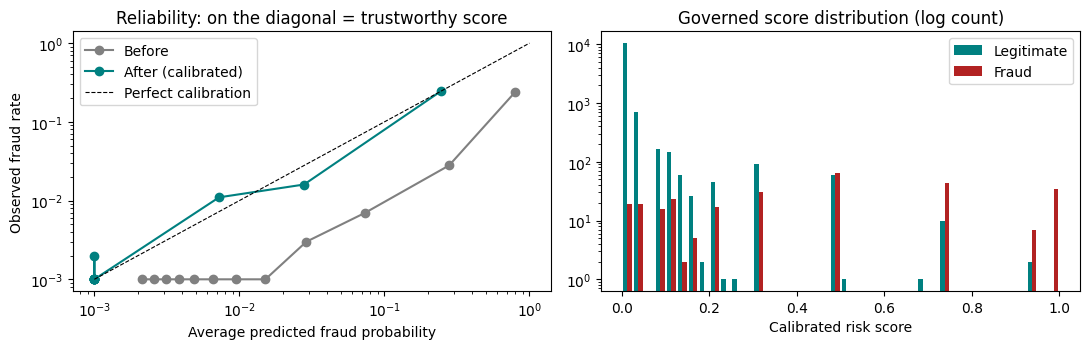

In [ ]:
governed = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                          l2_regularization=1.0, random_state=0)
governed.fit(train[FEATURES_GOV], train.is_fraud)
calibrator = IsotonicRegression(out_of_bounds='clip').fit(governed.predict_proba(valid[FEATURES_GOV])[:, 1], valid.is_fraud)
def risk_score(df):
    return calibrator.predict(governed.predict_proba(df[FEATURES_GOV])[:, 1])

def ece(y, p, bins=10):
    edges = np.quantile(p, np.linspace(0, 1, bins + 1)); idx = np.clip(np.searchsorted(edges, p, side='right') - 1, 0, bins - 1)
    return sum((idx == b).mean() * abs(np.mean(y[idx == b]) - np.mean(p[idx == b])) for b in range(bins) if (idx == b).any())

y_test = test.is_fraud.values
p_test = risk_score(test)
measure = pd.DataFrame({
    'Model': ['Before (balanced, all features)', 'After (approved features, calibrated)'],
    'AUC': [roc_auc_score(y_test, test_scores_before), roc_auc_score(y_test, p_test)],
    'Brier score (lower=better)': [brier_score_loss(y_test, test_scores_before), brier_score_loss(y_test, p_test)],
    'Expected calibration error': [ece(y_test, test_scores_before), ece(y_test, p_test)],
    'Mean score vs true fraud rate': [f'{test_scores_before.mean():.3f} vs {y_test.mean():.3f}', f'{p_test.mean():.3f} vs {y_test.mean():.3f}'],
}).round(4)
display(measure)

# Is the model equally good at spotting fraud in both segments?
display(pd.DataFrame({s: {'AUC before': roc_auc_score(y_test[test.segment==s], test_scores_before[test.segment==s]),
                          'AUC after': roc_auc_score(y_test[test.segment==s], p_test[test.segment==s]),
                          'Fraud rate': y_test[test.segment==s].mean()} for s in SEGMENTS}).round(3))

# Robustness: nudging amount and distance by up to 10% shouldn't swing the score much
noisy = test.copy(); r = np.random.default_rng(7)
for c in ['amount_pkr', 'distance_km']: noisy[c] = noisy[c] * r.uniform(0.9, 1.1, len(noisy))
shift = np.abs(risk_score(noisy) - p_test)
print(f'Robustness check: typical score change {np.median(shift):.4f}, and 99% of changes are below {np.quantile(shift, 0.99):.4f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for scores, lab, col in [(test_scores_before, 'Before', 'grey'), (p_test, 'After (calibrated)', 'teal')]:
    q = pd.qcut(pd.Series(scores).rank(method='first'), 12)          # 12 equal-size groups of payments
    g = pd.DataFrame({'p': scores, 'y': y_test}).groupby(q.values, observed=True).mean().clip(lower=1e-3)
    ax[0].plot(g.p, g.y, 'o-', color=col, label=lab)
ax[0].plot([1e-3, 1], [1e-3, 1], 'k--', lw=0.8, label='Perfect calibration')
ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlabel('Average predicted fraud probability')
ax[0].set_ylabel('Observed fraud rate'); ax[0].set_title('Reliability: on the diagonal = trustworthy score'); ax[0].legend()
ax[1].hist([p_test[y_test==0], p_test[y_test==1]], bins=40, log=True, label=['Legitimate', 'Fraud'], color=['teal', 'firebrick'])
ax[1].set_title('Governed score distribution (log count)'); ax[1].set_xlabel('Calibrated risk score'); ax[1].legend()
plt.tight_layout(); plt.show()
_ = audit.record('MEASURE_COMPLETED', auc=round(roc_auc_score(y_test, p_test), 4), ece=round(ece(y_test, p_test), 4), by='Model Risk (2nd line)')

### Measurement assurance note — calibration and generalization
The isotonic calibrator and the policy thresholds both use month 4. This is a valid classroom demonstration with a separate month 5 test, but tuning repeatedly on the calibration sample can overfit that month. The calibration plot and ECE depend on binning, and a low ECE does not guarantee good calibration for every segment or week. The perturbation experiment checks two numeric inputs only; it is not a comprehensive robustness or adversarial test.

## Part 12: Manage how decisions are made, reviewed, appealed and monitored

A good score is only half the job. We still have to decide what to do with each payment. Instead of a single "block" cut-off, each payment now gets one of three outcomes:

- **Allow** when the risk is low, so the payment goes straight through;
- **Extra check** when we're unsure. The customer confirms with an OTP or fingerprint and an analyst takes a look. Most genuine customers get through;
- **Block** when the risk is very high. The customer is told why and how to appeal.

We pick the two cut-offs on month 4 by searching for the cheapest option that stays inside every policy limit. The policy picks the operating point, not the accuracy headline.

Sometimes the limits can't all be met at once. When that happens the code doesn't let the engineer quietly relax one. It reports the conflict and passes it to the person who is accountable, and their decision goes in the audit log as a new version of the policy. Adding analyst capacity, with a recorded sign-off, is good governance. Loosening a harm limit after seeing the results is moving the goalposts.

The assumptions behind this part, which you can change:
- analysts approve genuine payments correctly 97% of the time and catch 92% of the fraud they review;
- each review costs PKR 150;
- the hassle of an extra check costs a genuine customer the equivalent of PKR 300.

Tried 1524 pairs of cut-offs; 0 meet every limit in FRAUD-RISK-POLICY v1.0 (illustrative).
Conflict: to meet every harm limit, at least 4.78% of payments must go to review, but we only planned for 4.50%.
Passed to the CTO, who owns the risk limits. Options: (a) loosen a harm limit, or (b) pay for more analysts.
The CTO chose (b): FRAUD-RISK-POLICY v1.1 (illustrative) raises review capacity to 6%. Options that now meet every limit: 100


,Chosen operating point (validation)
t_review,8.000000e-02
t_block,5.000000e-01
expected_cost,1.726855e+06
customer_false_block_rate,2.400000e-03
recall,7.456000e-01
review_rate,4.780000e-02
max_seg_auto_fpr,3.500000e-03
seg_gap_pp,4.491000e-01


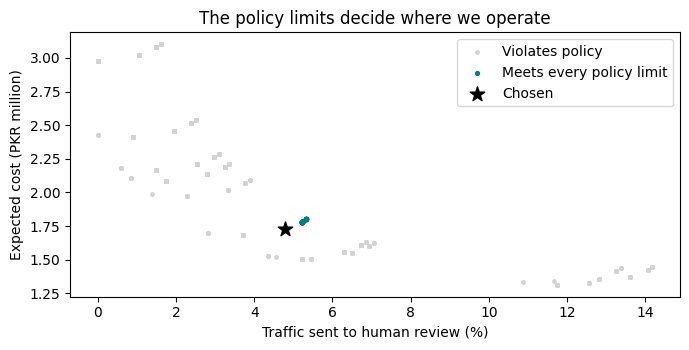

In [ ]:
REVIEW = {'legit_pass': 0.97, 'fraud_catch': 0.92, 'cost_review': 150, 'cost_friction': 300}

def evaluate_policy(y, p, seg, t_review, t_block):
    block, review = p >= t_block, (p >= t_review) & (p < t_block)
    legit, fraud = (y == 0), (y == 1)
    exp_false_block = (block & legit).sum() + (review & legit).sum() * (1 - REVIEW['legit_pass'])
    exp_missed = ((p < t_review) & fraud).sum() + (review & fraud).sum() * (1 - REVIEW['fraud_catch'])
    cost = (exp_false_block * COST_FALSE_BLOCK + exp_missed * COST_MISSED_FRAUD
            + review.sum() * REVIEW['cost_review'] + (review & legit).sum() * REVIEW['cost_friction'])
    seg_fpr = [(block & legit & (seg == s)).sum() / (legit & (seg == s)).sum() for s in SEGMENTS]
    seg_final = [((block & legit & (seg == s)).sum() + (review & legit & (seg == s)).sum() * (1 - REVIEW['legit_pass']))
                 / (legit & (seg == s)).sum() for s in SEGMENTS]                 # expected genuine payments blocked
    return {'t_review': t_review, 't_block': t_block, 'expected_cost': cost,
            'customer_false_block_rate': exp_false_block / legit.sum(), 'recall': 1 - exp_missed / fraud.sum(),
            'review_rate': review.mean(), 'max_seg_auto_fpr': max(seg_fpr), 'seg_gap_pp': 100 * abs(seg_final[1] - seg_final[0])}

p_valid, y_valid, s_valid = risk_score(valid), valid.is_fraud.values, valid.segment.values
grid = pd.DataFrame([evaluate_policy(y_valid, p_valid, s_valid, tr, tb)
                     for tr in np.arange(0.02, 0.50, 0.01) for tb in np.arange(0.30, 1.00, 0.02) if tb > tr + 0.05])
def harm_limits_ok(g):     # the harm limits (H1 to H3) are never loosened
    return ((g.customer_false_block_rate <= POLICY['max_customer_false_block_rate'])
            & (g.max_seg_auto_fpr <= POLICY['max_auto_block_fpr_per_segment'])
            & (g.seg_gap_pp <= POLICY['max_segment_fpr_gap_pp']) & (g.recall >= POLICY['min_fraud_recall']))
def feasible_set(g):
    return g[harm_limits_ok(g) & (g.review_rate <= POLICY['max_review_rate'] * POLICY['capacity_planning_buffer'])]

feasible = feasible_set(grid)
print(f"Tried {len(grid)} pairs of cut-offs; {len(feasible)} meet every limit in {POLICY['policy_version']}.")
if feasible.empty:
    # Govern in action: the limits clash. The engineer may not loosen a harm limit; the accountable owner decides.
    needed = grid.loc[harm_limits_ok(grid), 'review_rate'].min()
    print(f'Conflict: to meet every harm limit, at least {needed:.2%} of payments must go to review, '
          f"but we only planned for {POLICY['max_review_rate'] * POLICY['capacity_planning_buffer']:.2%}.")
    print('Passed to the CTO, who owns the risk limits. Options: (a) loosen a harm limit, or (b) pay for more analysts.')
    new_capacity = np.ceil(needed / POLICY['capacity_planning_buffer'] * 100) / 100
    POLICY = {**POLICY, 'policy_version': 'FRAUD-RISK-POLICY v1.1 (illustrative)', 'max_review_rate': new_capacity}
    audit.record('POLICY_CHANGE', version=POLICY['policy_version'], change=f'review capacity raised to {new_capacity:.0%} of payments',
                 rationale='Harm limits unchanged; option (b) funded', approved_by='CTO', decided_on='validation data only')
    feasible = feasible_set(grid)
    print(f"The CTO chose (b): {POLICY['policy_version']} raises review capacity to {new_capacity:.0%}. Options that now meet every limit: {len(feasible)}")
chosen = feasible.sort_values('expected_cost').iloc[0]
T_REVIEW, T_BLOCK = round(float(chosen.t_review), 2), round(float(chosen.t_block), 2)
display(chosen.to_frame('Chosen operating point (validation)').round(4))
audit.record('THRESHOLDS_APPROVED', t_review=T_REVIEW, t_block=T_BLOCK, by='Fraud Product Lead', reviewed_by='CAIGO')

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.scatter(grid.review_rate * 100, grid.expected_cost / 1e6, s=6, color='lightgrey', label='Violates policy')
ax.scatter(feasible.review_rate * 100, feasible.expected_cost / 1e6, s=8, color='teal', label='Meets every policy limit')
ax.scatter([chosen.review_rate * 100], [chosen.expected_cost / 1e6], s=120, marker='*', color='black', label='Chosen')
ax.set_xlabel('Traffic sent to human review (%)'); ax.set_ylabel('Expected cost (PKR million)')
ax.set_title('The policy limits decide where we operate'); ax.legend(); plt.tight_layout(); plt.show()

### Policy cost and reviewer-assumption note
The expected-cost equation intentionally retains the existing amounts: **PKR 1,500** per false block, **PKR 20,000** per missed fraud, **PKR 150** per review, and **PKR 300** friction per reviewed legitimate payment. It treats automatic blocks as stopping fraud and models reviewer performance using **97% legitimate-pass** and **92% fraud-catch** assumptions. These are *simulation parameters*, not measured reviewer performance. The estimate excludes other possible losses, investigation costs, appeal delays, and downstream recovery. Threshold selection uses the same month 4 used for calibration; evaluate generalization on held-out periods.

### Running the new process on the test month

Every decision is logged with the model version, policy version, score and plain-language reason codes, so we can explain it to the customer and handle appeals. Human review and appeals are simulated using the assumptions above. The code checks the emergency safety switch on every call. While it's on, the model can't block anyone, and every risky payment goes to a person instead.

In [ ]:
def reason_codes(row):
    codes = []
    if row.new_device: codes.append('NEW_DEVICE')
    if row.txn_velocity_1h >= 3: codes.append('HIGH_VELOCITY')
    if row.merchant_risk >= 0.35: codes.append('HIGH_RISK_MERCHANT')
    if row.failed_pin > 0: codes.append('FAILED_PIN')
    if row.hour <= 4: codes.append('NIGHT_TIME')
    if row.amount_pkr >= 15000: codes.append('LARGE_AMOUNT')
    return codes or ['MODEL_PATTERN']

def governed_decide(df, rng):
    p = risk_score(df)
    if KILL_SWITCH['active']:
        action = np.where(p >= T_REVIEW, 'STEP-UP REVIEW', 'ALLOW')       # with the switch on, the model can't block anyone
    else:
        action = np.select([p >= T_BLOCK, p >= T_REVIEW], ['BLOCK', 'STEP-UP REVIEW'], 'ALLOW')
    y = df.is_fraud.values; u = rng.random(len(df))
    # What the analyst decides for each reviewed payment (simulated)
    reviewer_blocks = np.where(y == 1, u < REVIEW['fraud_catch'], u > REVIEW['legit_pass'])
    final_blocked = (action == 'BLOCK') | ((action == 'STEP-UP REVIEW') & reviewer_blocks)
    out = df[['txn_id', 'month', 'week', 'segment', 'is_fraud']].copy()
    out['risk_score'], out['action'], out['final_blocked'] = p.round(4), action, final_blocked
    flagged = action != 'ALLOW'
    out['reason_codes'] = ''
    out.loc[flagged, 'reason_codes'] = [','.join(reason_codes(r)) for r in df[flagged].itertuples()]
    return out

decisions = governed_decide(test, np.random.default_rng(11))
for r in decisions[decisions.action != 'ALLOW'].itertuples():
    audit.record('DECISION', txn_id=r.txn_id, model=model_registry['version'], policy=POLICY['policy_version'],
                 score=r.risk_score, action=r.action, final_blocked=bool(r.final_blocked), reasons=r.reason_codes)

# Appeals: we assume 60% of wrongly blocked customers appeal, and a second analyst restores 95% of them within 24 hours
false_blocks = decisions[(decisions.final_blocked) & (decisions.is_fraud == 0)]
ar = np.random.default_rng(12)
appealed = false_blocks[ar.random(len(false_blocks)) < 0.60]
reinstated = appealed[ar.random(len(appealed)) < 0.95]
for r in appealed.itertuples():
    audit.record('APPEAL', txn_id=r.txn_id, outcome='REINSTATED' if r.txn_id in set(reinstated.txn_id) else 'UPHELD')

review_cost = (decisions.action == 'STEP-UP REVIEW').sum() * REVIEW['cost_review'] \
              + ((decisions.action == 'STEP-UP REVIEW') & (decisions.is_fraud == 0)).sum() * REVIEW['cost_friction']
after = outcome_metrics(decisions.is_fraud, decisions.final_blocked, decisions.segment, 'After governance', extra_cost=review_cost)
auto_fpr = {s: ((decisions.action == 'BLOCK') & (decisions.is_fraud == 0) & (decisions.segment == s)).sum()
               / ((decisions.is_fraud == 0) & (decisions.segment == s)).sum() for s in SEGMENTS}

display(decisions.action.value_counts().to_frame('Test-month decisions'))
display(pd.crosstab(decisions.segment, decisions.action, normalize='index').round(4))
print('Genuine payments blocked automatically:', ', '.join(f'{k} {v:.2%}' for k, v in auto_fpr.items()))
print(f'Genuine customers wrongly blocked: {len(false_blocks)}. Appealed: {len(appealed)}. Restored within 24 hours: {len(reinstated)}.')
display(audit.frame().query("event == 'DECISION'").head(5)[['seq', 'txn_id', 'score', 'action', 'final_blocked', 'reasons', 'hash']])

# Kill switch drill: someone without authority can't stop the model; someone with authority can.
try: set_kill_switch(True, 'Marketing Manager', 'drill')
except PermissionError as e: print('Drill, step 1:', e)
set_kill_switch(True, 'Head of MLOps', 'Quarterly kill switch drill')
drill = governed_decide(test.head(2000), np.random.default_rng(1))
print('Drill, step 2: kill switch on. Payments blocked automatically:', int((drill.action == 'BLOCK').sum()))
set_kill_switch(False, 'Head of MLOps', 'Drill finished')

,Test-month decisions
action,
ALLOW,11327
STEP-UP REVIEW,575
BLOCK,98


action,ALLOW,BLOCK,STEP-UP REVIEW
segment,,,
Established,0.9714,0.0024,0.0262
New-to-digital,0.8782,0.0220,0.0997


Genuine payments blocked automatically: Established 0.04%, New-to-digital 0.33%
Genuine customers wrongly blocked: 29. Appealed: 17. Restored within 24 hours: 17.


,seq,txn_id,score,action,final_blocked,reasons,hash
6,6,T048003,0.1156,STEP-UP REVIEW,False,"NEW_DEVICE,NIGHT_TIME",492c356c4688ea60
7,7,T048010,0.7358,BLOCK,True,"HIGH_VELOCITY,HIGH_RISK_MERCHANT,NIGHT_TIME",3fd2aac92ea7f24d
8,8,T048038,0.3084,STEP-UP REVIEW,False,"NEW_DEVICE,NIGHT_TIME",86ed6ebe6f571ccc
9,9,T048042,0.1156,STEP-UP REVIEW,True,NEW_DEVICE,279aad9f11c5525b
10,10,T048049,0.1156,STEP-UP REVIEW,True,HIGH_VELOCITY,a2aa0cfe37a08438


Drill, step 1: Marketing Manager is not allowed to use the kill switch
Drill, step 2: kill switch on. Payments blocked automatically: 0


### Decision transparency and human review note
The `reason_codes()` output uses hand-authored feature rules. It provides operational flags, **not verified feature attribution for the gradient-boosting model**. In `governed_decide()`, simulated reviewer outcomes are generated using the known `is_fraud` ground truth. Real reviewers do not know the true label at decision time. This approach is useful for teaching expected human-in-the-loop performance but must not be represented as a live reviewer evaluation.

### Monitoring, drift and incident response

Next we let the model run into month 6, the future month we set aside at the start. A big onboarding campaign changes who the customers are, and fraud goes up. Good management needs three things here: monitors with triggers agreed in advance, a record of every incident, and a fix that is itself tested before anyone switches it on.

We watch four signals: how far the score distribution has shifted (PSI), the share of genuine customers blocked, how busy the review team is, and whether the average score still matches the fraud rate we actually see as labels come in. When something trips, we recalibrate using the first two weeks of month 6 and check the result on the last two weeks. While an incident is open, the stop conditions in the policy decide whether the model keeps running.

,week,month,score_PSI,customer_false_block_rate,fraud_recall,review_rate,new_to_digital_share,mean_score_minus_fraud_rate,status
0,17,5,4.9182,0.0014,0.7647,0.0453,0.3030,-0.0002,ROLLBACK
1,18,5,4.8938,0.0024,0.8356,0.0523,0.2997,0.0007,ROLLBACK
2,19,5,4.9038,0.0027,0.7015,0.0497,0.2850,0.0019,ROLLBACK
3,20,5,4.9212,0.0017,0.7746,0.0443,0.2923,0.0003,ROLLBACK
4,21,6,4.8117,0.0011,0.6793,0.0647,0.5427,-0.0307,ROLLBACK
5,22,6,4.8221,0.0021,0.6721,0.0673,0.5500,-0.0297,ROLLBACK
6,23,6,4.8418,0.0014,0.7044,0.0633,0.5490,-0.0247,ROLLBACK
7,24,6,4.8260,0.0018,0.6824,0.0667,0.5427,-0.0236,ROLLBACK


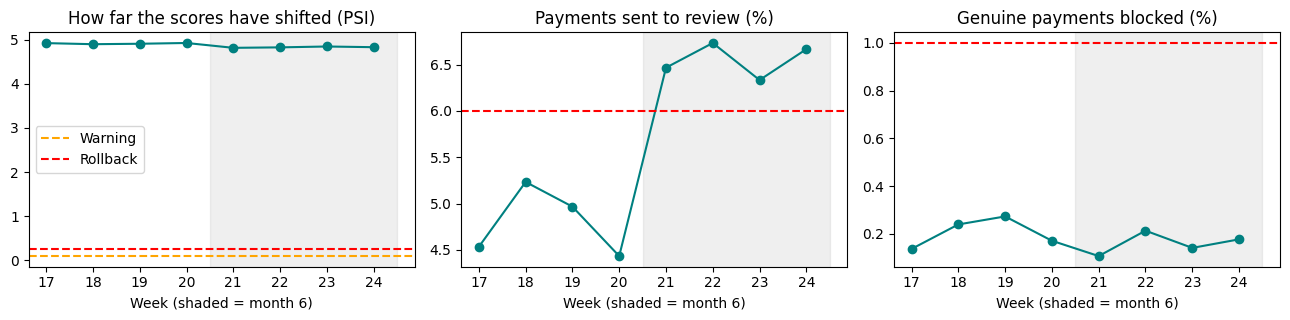

,Calibrator,ECE on weeks 23-24,Mean score,True fraud rate
0,Old (validation month),0.0243,0.0307,0.0548
1,Recalibrated (drift month),0.0089,0.0601,0.0548


The fix worked on fresh data and is approved for use.
The audit log now holds 700 entries, and nothing in it has been altered.


In [ ]:
def psi(expected, actual, bins=10):
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected) + 1e-6; a = np.histogram(actual, edges)[0] / len(actual) + 1e-6
    return float(np.sum((a - e) * np.log(a / e)))

ref_scores = risk_score(valid)
monitor = []
for wk, g in pd.concat([test, future]).groupby('week'):
    d = governed_decide(g, np.random.default_rng(int(wk)))
    legit = d.is_fraud == 0
    monitor.append({'week': int(wk), 'month': int(g.month.iloc[0]), 'score_PSI': psi(ref_scores, d.risk_score.values),
                    'customer_false_block_rate': (d.final_blocked & legit).sum() / legit.sum(),
                    'fraud_recall': (d.final_blocked & ~legit).sum() / max((~legit).sum(), 1),
                    'review_rate': (d.action == 'STEP-UP REVIEW').mean(),
                    'new_to_digital_share': (g.segment == 'New-to-digital').mean(),
                    'mean_score_minus_fraud_rate': d.risk_score.mean() - g.is_fraud.mean()})
monitor = pd.DataFrame(monitor)
monitor['status'] = np.select([monitor.score_PSI >= POLICY['psi_rollback'],
                               (monitor.score_PSI >= POLICY['psi_warning'])
                               | (monitor.customer_false_block_rate > POLICY['max_customer_false_block_rate'])
                               | (monitor.review_rate > POLICY['max_review_rate'])
                               | (monitor.mean_score_minus_fraud_rate.abs() > POLICY['max_calibration_error'] / 2)],
                              ['ROLLBACK', 'INCIDENT'], 'OK')
display(monitor.round(4))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
ax[0].plot(monitor.week, monitor.score_PSI, 'o-', color='teal'); ax[0].axhline(POLICY['psi_warning'], color='orange', ls='--', label='Warning')
ax[0].axhline(POLICY['psi_rollback'], color='red', ls='--', label='Rollback'); ax[0].set_title('How far the scores have shifted (PSI)'); ax[0].legend()
ax[1].plot(monitor.week, monitor.review_rate * 100, 'o-', color='teal'); ax[1].axhline(POLICY['max_review_rate'] * 100, color='red', ls='--')
ax[1].set_title('Payments sent to review (%)')
ax[2].plot(monitor.week, monitor.customer_false_block_rate * 100, 'o-', color='teal'); ax[2].axhline(POLICY['max_customer_false_block_rate'] * 100, color='red', ls='--')
ax[2].set_title('Genuine payments blocked (%)')
for a in ax: a.axvspan(20.5, 24.5, color='grey', alpha=0.12); a.set_xlabel('Week (shaded = month 6)')
plt.tight_layout(); plt.show()

incidents = monitor[monitor.status != 'OK']
if len(incidents):
    first = incidents.iloc[0]
    audit.record('INCIDENT_OPENED', week=int(first.week), status=first.status, psi=round(first.score_PSI, 3),
                 owner='Head of MLOps', action='Recalibrate on recent labels; validate before release')
    # The fix: recalibrate on weeks 21-22 and check it on weeks 23-24 (in real life, labels arrive a little late)
    recal_fit, recal_test = future[future.week <= 22], future[future.week >= 23]
    new_cal = IsotonicRegression(out_of_bounds='clip').fit(governed.predict_proba(recal_fit[FEATURES_GOV])[:, 1], recal_fit.is_fraud)
    raw = governed.predict_proba(recal_test[FEATURES_GOV])[:, 1]
    yv = recal_test.is_fraud.values
    resp = pd.DataFrame({'Calibrator': ['Old (validation month)', 'Recalibrated (drift month)'],
                         'ECE on weeks 23-24': [ece(yv, calibrator.predict(raw)), ece(yv, new_cal.predict(raw))],
                         'Mean score': [calibrator.predict(raw).mean(), new_cal.predict(raw).mean()],
                         'True fraud rate': [yv.mean()] * 2}).round(4)
    display(resp)
    accepted = bool(resp.iloc[1, 1] <= POLICY['max_calibration_error'] and resp.iloc[1, 1] < resp.iloc[0, 1])
    audit.record('INCIDENT_RESPONSE', change='recalibration', validated=bool(accepted),
                 approved_by='Model Risk (2nd line)' if accepted else None)
    print('The fix worked on fresh data and is approved for use.' if accepted else 'The fix did not hold up. Keep the incident open and send more payments to review.')
else:
    print('No monitoring alarms went off.')
print(f'The audit log now holds {len(audit.entries)} entries, and ' + ('nothing in it has been altered.' if audit.verify() else 'SOMETHING IN IT HAS BEEN ALTERED.'))

### Drift monitoring note
PSI compares the distributions of reference and current risk scores. The notebook's formula uses reference quantile bins and adds a small epsilon to avoid log-zero errors; because the smoothed proportions are not renormalized, the reported PSI is a close approximation to the unsmoothed formula. PSI can flag score-distribution change but cannot alone identify its cause, prove bias, or determine that the model is unsafe. Alerts require supporting evidence such as subgroup false blocks, fraud recall, reviewer capacity and calibration.

## Part 13: Before and after

Same data, same test month, same cost assumptions. The "before" column is the system you examined in Parts 1 and 2. Notice that the model's ability to rank fraud (its AUC) hardly changes. Most of the improvement comes from what governance changes around the model: which features it's allowed to use, how its scores are read, who looks at the uncertain cases and how customers are treated when it gets things wrong.

Check passed: the 'before' figures match Parts 1 and 2 (386 genuine payments blocked, 63 frauds missed, PKR 1,839,000 cost).


System,Before governance,After governance
Accuracy,0.9626,0.9922
Fraud recall,0.7742,0.7670
Precision of blocks,0.3588,0.8807
False-positive rate,0.0329,0.0025
Legit payments blocked,386,29
Fraud missed,63,65
FPR Established,0.0174,0.0008
FPR New-to-digital,0.0716,0.0066
Segment FPR gap (pp),5.4154,0.5727
Total cost (PKR),"1,839,000","1,559,950"


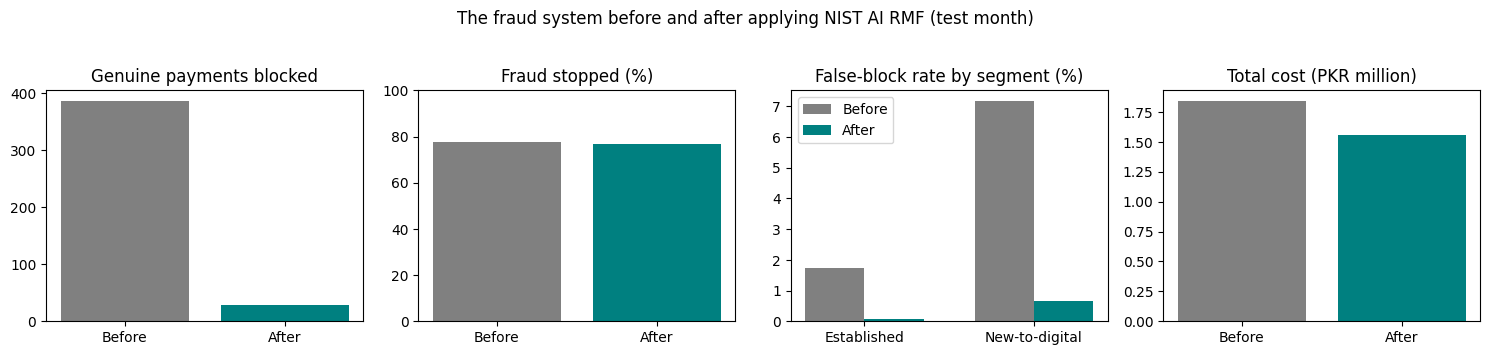

Genuine payments blocked went from 386 to 29 (92% fewer).
The gap between segments went from 5.42 to 0.57 percentage points.
Total cost went from PKR 1,839,000 to PKR 1,559,950, and the new figure already includes PKR 216,450 for reviews.


In [ ]:
before = outcome_metrics(test.is_fraud, blocked_before, test.segment, 'Before governance')
# The 'before' system must be exactly the one analysed in Parts 1 and 2
assert before['Legit payments blocked'] == fp and before['Fraud missed'] == fn
assert before['Total cost (PKR)'] == cost_fp + cost_fn and abs(before['Accuracy'] - metrics['Accuracy']) < 1e-12
print(f"Check passed: the 'before' figures match Parts 1 and 2 ({fp} genuine payments blocked, {fn} frauds missed, PKR {cost_fp + cost_fn:,} cost).")

comparison_ba = pd.DataFrame([before, after]).set_index('System').T
fmt = lambda v: f'{v:,.4f}' if isinstance(v, (float, np.floating)) and abs(v) < 10 else f'{v:,.0f}'
display(comparison_ba.apply(lambda col: col.map(fmt)))

fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
lbl = ['Before', 'After']; col = ['grey', 'teal']
ax[0].bar(lbl, [before['Legit payments blocked'], after['Legit payments blocked']], color=col); ax[0].set_title('Genuine payments blocked')
ax[1].bar(lbl, [before['Fraud recall'] * 100, after['Fraud recall'] * 100], color=col); ax[1].set_title('Fraud stopped (%)'); ax[1].set_ylim(0, 100)
x = np.arange(2); w = 0.35
ax[2].bar(x - w/2, [before['FPR Established'] * 100, before['FPR New-to-digital'] * 100], w, color='grey', label='Before')
ax[2].bar(x + w/2, [after['FPR Established'] * 100, after['FPR New-to-digital'] * 100], w, color='teal', label='After')
ax[2].set_xticks(x, SEGMENTS); ax[2].set_title('False-block rate by segment (%)'); ax[2].legend()
ax[3].bar(lbl, [before['Total cost (PKR)'] / 1e6, after['Total cost (PKR)'] / 1e6], color=col); ax[3].set_title('Total cost (PKR million)')
plt.suptitle('The fraud system before and after applying NIST AI RMF (test month)', y=1.03); plt.tight_layout(); plt.show()

print(f"Genuine payments blocked went from {before['Legit payments blocked']} to {after['Legit payments blocked']} "
      f"({1 - after['Legit payments blocked'] / before['Legit payments blocked']:.0%} fewer).")
print(f"The gap between segments went from {before['Segment FPR gap (pp)']:.2f} to {after['Segment FPR gap (pp)']:.2f} percentage points.")
print(f"Total cost went from PKR {before['Total cost (PKR)']:,.0f} to PKR {after['Total cost (PKR)']:,.0f}, and the new figure already includes PKR {review_cost:,.0f} for reviews.")

### How sure can we be?

One month of data is just one sample, so the improvement could partly be luck. Resampling the test month 500 times (bootstrapping) gives a range for each figure. That range belongs in front of the CTO before anyone signs.

In [ ]:
br = np.random.default_rng(99); B = 500; n = len(test); rows = []
yb, sb = test.is_fraud.values, test.segment.values
blk_b, blk_a = blocked_before, decisions.final_blocked.values
for _ in range(B):
    i = br.integers(0, n, n)
    m_b = outcome_metrics(yb[i], blk_b[i], sb[i], 'b'); m_a = outcome_metrics(yb[i], blk_a[i], sb[i], 'a')
    rows.append({'FPR before': m_b['False-positive rate'], 'FPR after': m_a['False-positive rate'],
                 'Recall before': m_b['Fraud recall'], 'Recall after': m_a['Fraud recall'],
                 'Gap before (pp)': m_b['Segment FPR gap (pp)'], 'Gap after (pp)': m_a['Segment FPR gap (pp)']})
boot = pd.DataFrame(rows)
ci = boot.quantile([0.025, 0.5, 0.975]).T; ci.columns = ['2.5%', 'median', '97.5%']
display(ci.round(4))
fpr_ci_upper_after = ci.loc['FPR after', '97.5%']
recall_ci_lower_after = ci.loc['Recall after', '2.5%']
print(f'Even at the pessimistic end of the range, {fpr_ci_upper_after:.2%} of genuine payments are blocked (limit {POLICY["max_customer_false_block_rate"]:.0%}).')
print(f'And at least {recall_ci_lower_after:.1%} of fraud is caught (minimum {POLICY["min_fraud_recall"]:.0%}).')

,2.5%,median,97.5%
FPR before,0.0295,0.0329,0.0363
FPR after,0.0016,0.0025,0.0034
Recall before,0.7279,0.7745,0.8196
Recall after,0.7129,0.7667,0.8139
Gap before (pp),4.5558,5.4055,6.4486
Gap after (pp),0.3116,0.5655,0.8724


Even at the pessimistic end of the range, 0.34% of genuine payments are blocked (limit 1%).
And at least 71.3% of fraud is caught (minimum 70%).


### NIST maturity, this time backed by evidence

Back in Part 4 the maturity scores were educated guesses. Now each function is scored from a checklist. An item is ticked only if the evidence exists in this notebook, and the code checks that for itself. The 0 to 5 scale is still our own teaching device rather than an official NIST score, but now every point can be traced to something real.

Some items can't be produced by code at all: a board-approved AI policy, staff training, and conversations with affected customers. They stay open, which is why the scores honestly stop short of 5.

In [ ]:
evidence = {
 'GOVERN': {'Risk limits written down as versioned code': 'policy_version' in POLICY,
            'One accountable person for every activity (RACI)': bool(raci.groupby('Activity').Accountable.nunique().eq(1).all()),
            'Model register with data fingerprints': 'training_data_hash' in model_registry,
            'Audit log checked and untouched': audit.verify(),
            'Kill switch limited to named roles, drill done': any(e['event'] == 'KILL_SWITCH' for e in audit.entries),
            'Board-approved enterprise AI policy': False,                       # still to do: needs people, not code
            'Staff training on AI risk completed': False},
 'MAP':    {'What the system is and is not for, written down': len(context_card) >= 5,
            'Each harm linked to a measure, a limit and an owner': len(harm_map) >= 5,
            'Proxy check done and features dropped': len(excluded) > 0,
            'Legal questions flagged for the lawyers': 'Regulatory notes (to verify)' in context_card.index,
            'Spoken with affected customers and merchants': False},
 'MEASURE':{'Tested on a later month the model never saw': test.month.min() > train.month.max(),
            'Scores calibrated and within the limit': ece(y_test, p_test) <= POLICY['max_calibration_error'],
            'Errors measured for each customer segment': 'FPR New-to-digital' in after,
            'Ranges worked out by bootstrapping': len(boot) == B,
            'Robustness check passed': np.quantile(shift, 0.99) < 0.05,
            'Independent re-test on a fresh sample': False},           # done in Part 14
 'MANAGE': {'Cut-offs chosen within the policy limits': len(feasible) > 0,
            'People review the uncertain cases': (decisions.action == 'STEP-UP REVIEW').any(),
            'Every flagged payment comes with reasons': (decisions.loc[decisions.action != 'ALLOW', 'reason_codes'] != '').all(),
            'Appeals handled and logged': any(e['event'] == 'APPEAL' for e in audit.entries),
            'Drift monitoring with alarms': 'status' in monitor,
            'Incident handled and the fix tested': any(e['event'] == 'INCIDENT_RESPONSE' and e['validated'] for e in audit.entries)},
}
def maturity(ev): return {f: round(float(5 * np.mean(list(items.values()))), 1) for f, items in ev.items()}
nist_after = maturity(evidence)
nist_before = dict(zip(nist.Function, nist['Illustrative maturity / 5']))
display(pd.DataFrame({'Before (Part 4 guess)': nist_before, 'After (from evidence)': nist_after}))
display(pd.DataFrame([(f, item, '✔' if ok else '✘ still to do') for f, items in evidence.items() for item, ok in items.items()],
                     columns=['Function', 'Evidence item', 'Status']))

,Before (Part 4 guess),After (from evidence)
GOVERN,1,3.6
MAP,2,4.0
MEASURE,2,4.2
MANAGE,1,5.0


,Function,Evidence item,Status
0,GOVERN,Risk limits written down as versioned code,✔
1,GOVERN,One accountable person for every activity (RACI),✔
2,GOVERN,Model register with data fingerprints,✔
3,GOVERN,Audit log checked and untouched,✔
4,GOVERN,"Kill switch limited to named roles, drill done",✔
5,GOVERN,Board-approved enterprise AI policy,✘ still to do
6,GOVERN,Staff training on AI risk completed,✘ still to do
7,MAP,"What the system is and is not for, written down",✔
8,MAP,"Each harm linked to a measure, a limit and an ...",✔
9,MAP,Proxy check done and features dropped,✔


### Evidence maturity note
The evidence checklist awards illustrative maturity points when particular code artifacts or logged events exist. A logged appeal or kill-switch event is evidence of a *simulated action*, not proof of a staffed, effective process. The 0–5 ratings are **not official NIST AI RMF maturity scores**. An actual assessment would require independent testing, operating procedures, sampled cases, and documented stakeholder approvals.

## Part 14: Run the release checks again, this time with evidence

These are the same checks as in Part 6, applied to the fraud system only. Two things are new, and both come from Govern:

- **An independent re-test.** The model risk team, who didn't build the model, generate a fresh sample themselves and run the frozen system on it. If it still stays within the limits, the re-test passes.
- **Human sign-offs, recorded explicitly.** Code can gather the evidence, but it can't sign on behalf of the legal team or the risk committee.

The loan model hasn't been through any of this, so the 25 point gap from Part 3 is still open. It gets its own decision.

In [ ]:
# Independent re-test: the model risk team draws a fresh month of data themselves
indep = make_transactions(12000, 5, np.random.default_rng(31337)); indep['segment_flag'] = (indep.segment == 'New-to-digital').astype(int)
indep.insert(0, 'txn_id', [f'I{i:06d}' for i in range(len(indep))]); indep['week'] = 0
indep_dec = governed_decide(indep, np.random.default_rng(5))
indep_m = outcome_metrics(indep_dec.is_fraud, indep_dec.final_blocked, indep_dec.segment, 'Independent re-test')
indep_pass = (indep_m['False-positive rate'] <= POLICY['max_customer_false_block_rate'] and indep_m['Fraud recall'] >= POLICY['min_fraud_recall']
              and indep_m['Segment FPR gap (pp)'] <= POLICY['max_segment_fpr_gap_pp'])
evidence['MEASURE']['Independent re-test on a fresh sample'] = indep_pass
nist_after = maturity(evidence)
audit.record('INDEPENDENT_RETEST', passed=indep_pass, fpr=round(indep_m['False-positive rate'], 4), by='Model Risk (2nd line)')
print(f"Independent re-test: {indep_m['False-positive rate']:.2%} of genuine payments blocked, {indep_m['Fraud recall']:.1%} of fraud caught, "
      f"segment gap {indep_m['Segment FPR gap (pp)']:.2f} points. Result: {'PASS' if indep_pass else 'FAIL'}")

SIGN_OFFS = {   # what each person has signed so far (made up for this exercise)
    'Model Risk (2nd line) validation': 'APPROVED' if indep_pass else 'REJECTED',
    'Chief AI Governance Officer': 'APPROVED FOR LIMITED PILOT',
    'Legal & Compliance (SBP / data protection review)': 'PENDING for full launch',
    'Internal Audit (3rd line)': 'SCHEDULED after the pilot',
}

gate_after = pd.DataFrame([
    ('Genuine payments blocked', after['False-positive rate'] <= POLICY['max_customer_false_block_rate'],
     f"Observed {after['False-positive rate']:.2%} (95% CI upper {fpr_ci_upper_after:.2%}); gate <= 1%"),
    ('Enough fraud caught', after['Fraud recall'] >= POLICY['min_fraud_recall'], f"Observed {after['Fraud recall']:.1%} (95% CI lower {recall_ci_lower_after:.1%}); gate >= 70%"),
    ('Gap between segments', after['Segment FPR gap (pp)'] <= POLICY['max_segment_fpr_gap_pp'], f"Observed {after['Segment FPR gap (pp)']:.2f} pp; gate <= 0.5 pp"),
    ('NIST maturity of 3 or more', all(v >= 3 for v in nist_after.values()), f'{nist_after}'),
    ('Appeals process', evidence['MANAGE']['Appeals handled and logged'], f'{len(appealed)} appeals logged, {len(reinstated)} customers restored'),
    ('Human review', evidence['MANAGE']['People review the uncertain cases'] and (decisions.action == 'STEP-UP REVIEW').mean() <= POLICY['max_review_rate'],
     f"{(decisions.action == 'STEP-UP REVIEW').mean():.2%} of payments reviewed; capacity {POLICY['max_review_rate']:.0%}"),
    ('Incident response', evidence['MANAGE']['Incident handled and the fix tested'],
     f"{len(incidents)} monitoring alerts; " + ('fix tested and working' if evidence['MANAGE']['Incident handled and the fix tested'] else 'fix not yet proven')),
    ('Independent validation', indep_pass, f"Model risk re-test {'passed' if indep_pass else 'failed'}; internal audit booked"),
], columns=['Gate', 'Passed', 'Evidence'])
# The same checks applied to the old system. Its controls didn't exist, so those checks fail automatically.
gate_before = [before['False-positive rate'] <= POLICY['max_customer_false_block_rate'], before['Fraud recall'] >= POLICY['min_fraud_recall'],
               before['Segment FPR gap (pp)'] <= POLICY['max_segment_fpr_gap_pp'], all(v >= 3 for v in nist_before.values()),
               False, False, False, False]
display(pd.DataFrame({'Gate': gate_after.Gate, 'Before governance': gate_before, 'After governance': gate_after.Passed,
                      'Evidence (after)': gate_after.Evidence}))

loan_module_gate = rate_gap <= limits['max_approval_gap']
print(f"Loan model (a separate system): approval gap still {rate_gap:.0%}, so it {'passes' if loan_module_gate else 'fails'}. We haven't worked on it here.")

Independent re-test: 0.23% of genuine payments blocked, 78.8% of fraud caught, segment gap 0.42 points. Result: PASS


,Gate,Before governance,After governance,Evidence (after)
0,Genuine payments blocked,False,True,Observed 0.25% (95% CI upper 0.34%); gate <= 1%
1,Enough fraud caught,True,True,Observed 76.7% (95% CI lower 71.3%); gate >= 70%
2,Gap between segments,False,False,Observed 0.57 pp; gate <= 0.5 pp
3,NIST maturity of 3 or more,False,True,"{'GOVERN': 3.6, 'MAP': 4.0, 'MEASURE': 5.0, 'M..."
4,Appeals process,False,True,"17 appeals logged, 17 customers restored"
5,Human review,False,True,4.79% of payments reviewed; capacity 6%
6,Incident response,False,True,8 monitoring alerts; fix tested and working
7,Independent validation,False,True,Model risk re-test passed; internal audit booked


Loan model (a separate system): approval gap still 25%, so it fails. We haven't worked on it here.


### Independent validation and policy coverage note
The “independent re-test” uses a fresh random seed, but draws from the **same synthetic data generator**. This checks reproducibility under the simulation assumptions, not external validity on independently sourced financial data. The eight release gates are a teaching subset of the written policy. In particular, the final gate list does **not separately enforce** `max_auto_block_fpr_per_segment`, even though threshold optimization checks it. This is examined in a supplemental read-only diagnostic after the notebook's original conclusion.

## Part 15: The CTO decides

The decision rule is agreed before anyone applies it:

- **Go (full launch)** if every check passes and every sign-off says APPROVED.
- **Conditional go (small live pilot)** if every check passes and the independent validation is approved, but some sign-offs are still pending. The pilot has a fixed scope, a fixed length and stop conditions that apply automatically.
- **No-go** if any check fails.

The CTO is the accountable owner in our responsibility table, so the decision is recorded under that role, and every piece of evidence behind it is in the audit log.

In [ ]:
def cto_decision(gates, sign_offs):
    if not gates.Passed.all(): return 'NO-GO'
    if all(v == 'APPROVED' for v in sign_offs.values()): return 'GO'
    if sign_offs['Model Risk (2nd line) validation'] == 'APPROVED': return 'CONDITIONAL GO - LIMITED PILOT'
    return 'NO-GO'

fraud_decision = cto_decision(gate_after, SIGN_OFFS)
loan_decision = 'NO-GO' if not loan_module_gate else 'REVIEW'
PILOT = {'traffic_share': '10% of wallet payments, in Karachi and Hyderabad only', 'duration': '8 weeks',
         'mode': 'Block automatically only at a score of %.2f or more; extra check from %.2f' % (T_BLOCK, T_REVIEW),
         'stop_conditions': [f"more than {POLICY['max_customer_false_block_rate']:.0%} of genuine payments blocked in any week",
                             f"segment gap above {POLICY['max_segment_fpr_gap_pp']} points", f"score drift (PSI) above {POLICY['psi_rollback']}",
                             f"more than {POLICY['max_review_rate']:.0%} of payments going to review, or appeals taking over 24 hours", 'any security or privacy incident'],
         'on_stop': 'Kill switch on, so payments go to people instead of being blocked, within 15 minutes; incident report to the CTO within 24 hours'}
model_registry['status'] = 'APPROVED FOR PILOT' if fraud_decision.startswith('CONDITIONAL') else ('PRODUCTION' if fraud_decision == 'GO' else 'REJECTED')
_ = audit.record('CTO_DECISION', fraud_module=fraud_decision, loan_module=loan_decision, by='CTO', pilot=PILOT['traffic_share'])

pilot_text = (f'''
TERMS OF THE PILOT
  Scope      : {PILOT['traffic_share']}, for {PILOT['duration']}
  How it runs: {PILOT['mode']}
  Stop if    : {'; '.join(PILOT['stop_conditions'])}
  If stopped : {PILOT['on_stop']}
''' if fraud_decision.startswith('CONDITIONAL') else '\nNo live payments may be touched. Shadow testing only until the failed checks are fixed.\n')
cto_memo = f'''PAYTRUST AI - DECISION RECORD FROM THE CTO
Date: {datetime.date.today():%d %B %Y}
Decided by: Chief Technology Officer (accountable owner)    Prepared by: Chief AI Governance Officer
Policy: {POLICY['policy_version']}
Model: {model_registry['model_id']} version {model_registry['version']}, trained on data with fingerprint {model_registry['training_data_hash']}

DECISION
  Fraud detection: {fraud_decision}
  Loan approvals : {loan_decision}. The 25 point approval gap hasn't been explained yet, so this model
                   needs its own Map and Measure work first.

WHAT CHANGED SINCE THE FIRST REVIEW                   BEFORE        AFTER
  Genuine payments blocked (test month)          {before['Legit payments blocked']:>8,}      {after['Legit payments blocked']:>8,}
  Share of genuine payments blocked              {before['False-positive rate']:>8.2%}      {after['False-positive rate']:>8.2%}
  Share of fraud stopped                         {before['Fraud recall']:>8.1%}      {after['Fraud recall']:>8.1%}
  Gap between segments (percentage points)       {before['Segment FPR gap (pp)']:>8.2f}      {after['Segment FPR gap (pp)']:>8.2f}
  Estimated total cost (PKR)                     {before['Total cost (PKR)']:>8,.0f}      {after['Total cost (PKR)']:>8,.0f}
  NIST maturity out of 5 (Gov/Map/Meas/Man)      {'/'.join(str(v) for v in nist_before.values()):>8}      {'/'.join(str(v) for v in nist_after.values()):>8}

WHY I'M COMFORTABLE WITH THIS
  Govern : the risk limits are written down and versioned, every activity has one owner, the audit log
           {'is intact' if audit.verify() else 'HAS BEEN ALTERED'}, and the kill switch has been tested.
           Changes made to the policy along the way: {'; '.join(e['change'] + ', approved by ' + e['approved_by'] for e in audit.entries if e['event'] == 'POLICY_CHANGE') or 'none'}.
  Map    : we dropped {' and '.join(excluded)} after the proxy check, and every harm has a measure and an owner.
  Measure: tested on an unseen month, scores well calibrated (error {ece(y_test, p_test):.4f}), checked for each segment,
           with confidence ranges and a robustness test. Independent re-test {'passed' if indep_pass else 'failed'}.
  Manage : uncertain payments go to people ({(decisions.action == 'STEP-UP REVIEW').mean():.1%} of payments), every flag comes with reasons,
           and {len(appealed)} appeals were handled. Monitoring raised {len(incidents)} alerts over weeks 17 to 24, and the fix
           {'was tested on fresh data and works' if evidence['MANAGE']['Incident handled and the fix tested'] else 'has NOT been shown to work yet'}.
  Checks that failed: {', '.join(gate_after.loc[~gate_after.Passed, 'Gate']) or 'none'}

WHAT STILL WORRIES ME
  In month 6 the review queue reached {monitor[monitor.month == 6].review_rate.max():.1%} of payments (capacity {POLICY['max_review_rate']:.0%}), and in one week
  only {monitor[monitor.month == 6].fraud_recall.min():.1%} of fraud was caught. The pilot stop conditions below would kick in if that happened,
  and we'll need a staffing plan before this grows.
{pilot_text}
BEFORE A FULL LAUNCH
  - Legal and Compliance view on SBP and data protection rules (currently {SIGN_OFFS['Legal & Compliance (SBP / data protection review)']})
  - Internal Audit to review what the pilot shows ({SIGN_OFFS['Internal Audit (3rd line)']})
  - Finish the open NIST items: a board-approved AI policy, staff training, and talking to affected customers
  - Run these checks again on pilot data. A full launch needs every sign-off to say APPROVED.

Signed: ______________________  Chief Technology Officer
(Synthetic teaching exercise. This is not a real approval.)
'''
print(cto_memo)
with open('paytrust_cto_decision.txt', 'w', encoding='utf-8') as f: f.write(cto_memo)
audit.frame().to_csv('paytrust_audit_log.csv', index=False)
print(f'Saved paytrust_cto_decision.txt and paytrust_audit_log.csv ({len(audit.entries)} log entries).')

PAYTRUST AI - DECISION RECORD FROM THE CTO
Date: 16 October 2026
Decided by: Chief Technology Officer (accountable owner)    Prepared by: Chief AI Governance Officer
Policy: FRAUD-RISK-POLICY v1.1 (illustrative)
Model: paytrust-fraud version 2.0-governed, trained on data with fingerprint 2ac43b0bcf8704a1

DECISION
  Fraud detection: NO-GO
  Loan approvals : NO-GO. The 25 point approval gap hasn't been explained yet, so this model
                   needs its own Map and Measure work first.

WHAT CHANGED SINCE THE FIRST REVIEW                   BEFORE        AFTER
  Genuine payments blocked (test month)               386            29
  Share of genuine payments blocked                 3.29%         0.25%
  Share of fraud stopped                            77.4%         76.7%
  Gap between segments (percentage points)           5.42          0.57
  Estimated total cost (PKR)                     1,839,000      1,559,950
  NIST maturity out of 5 (Gov/Map/Meas/Man)       1/2/2/1      3.6/4

### Deployment authorization note
The CTO rule can produce **CONDITIONAL GO LIMITED PILOT** with Legal & Compliance pending and Internal Audit scheduled. This is an **illustrative internal decision**, not a determination that live deployment is lawful or approved. Any real pilot must first satisfy applicable legal, regulatory, security, data protection and internal authorization requirements. Full launch should require all required approvals and independently verified operating controls. The loan module is evaluated separately.

### Questions for discussion

1. The model's AUC barely moved, yet far fewer genuine customers were blocked. Which NIST function deserves most of the credit, and why?
2. The new system catches a slightly different set of fraud cases than the old one. Would you accept catching a little less fraud in exchange for blocking far fewer genuine customers? Who should make that call, and where should it be written down?
3. The proxy check removed `account_age_days`. Can you think of a feature that predicts fraud *and* reveals the customer's segment? What should the Map step do in that case?
4. Change `REVIEW['legit_pass']` to 0.90 and run Parts 12 to 15 again. Does the CTO's decision change? Why is the quality of human reviewers a governance question and not only an operations one?
5. The CTO approved a pilot, not a full launch. Suggest one more stop condition and name its owner from the responsibility table.

## References

- [NIST AI RMF 1.0](https://airc.nist.gov/airmf-resources/airmf/)
- [NIST AI RMF Playbook](https://www.nist.gov/itl/ai-risk-management-framework/nist-ai-rmf-playbook)
- [EU AI Act, Annex III](https://ai-act-service-desk.ec.europa.eu/en/ai-act/annex-3)
- [OECD AI Principles](https://oecd.ai/en/ai-principles)
- [Pakistan National AI Policy 2025 (official PDF)](https://moitt.gov.pk/SiteImage/Misc/files/National%20AI%20Policy.pdf)

Laws and policies change, so check the latest versions before using any of this for a real decision.

### Class exercise (10 to 15 minutes)

Work in pairs. One of you argues for (A) no live launch, the other for (B) a small live pilot with human review. For your position, explain which safeguards, evidence and approvals you'd need. Remember that a shadow test, where the model scores payments but doesn't act on them, is very different from a live pilot where real customers are affected.

Then ask yourselves: would your answer change if fraud losses fell by 80% but the number of genuine payments blocked doubled? What evidence would you want to see before agreeing to a limited rollout?

## Final reflection: your name is on the decision

**At the first review (Part 8)** my answer was no to an unrestricted launch. The 96% figure hid a lot of customer friction, the loan model showed a large approval gap that hadn't been explained, and the basic safeguards weren't there. The only thing I'd allow at that stage was offline or shadow testing, with data protected and no real payments or loans affected.

**After the governance work (Parts 9 to 15)** the picture changes for the fraud system. Far fewer genuine customers are blocked, the gap between customer segments has narrowed sharply, there's human review and an appeals route, and the evidence has been re-tested independently. That's enough for a small, time-limited pilot with clear stop conditions, though not yet for a full launch. The loan model is a separate system and still hasn't been looked at properly, so it stays at no.

**Questions to answer in your own words:**
1. Which single number most undermines the "96% accuracy" claim, and why?
2. Does a difference in approval rates prove discrimination? What else would you test?
3. Why should the fraud model and the credit model be classified separately under the EU AI Act?
4. Who should be able to overrule the model's decisions, and who should be able to stop the whole system?
5. What exactly would you need to see before you signed a full "go"?



## Supplemental assurance checks (read-only; original results unchanged)
These checks make the remaining policy coverage visible without changing **any existing code, assumptions, thresholds, data, outputs or deployment decision**. They are a second, explicitly educational assessment; a failed check does not silently rewrite the CTO's original decision.

In [ ]:
# Read-only assurance: report controls that the original final gates do not explicitly enforce.
assurance_rows = []
for s in SEGMENTS:
    g = decisions[decisions.segment == s]
    legitimate = g.is_fraud == 0
    # Auto-block is the pre-review action, not a reviewer decision.
    auto_block = g.action == 'AUTO-BLOCK'
    rate = float((auto_block & legitimate).sum() / legitimate.sum()) if legitimate.any() else np.nan
    assurance_rows.append({'Check': f'Auto-block FPR — {s}',
                           'Observed': rate,
                           'Policy limit': POLICY['max_auto_block_fpr_per_segment'],
                           'Passed': bool(rate <= POLICY['max_auto_block_fpr_per_segment'])})
assurance = pd.DataFrame(assurance_rows)
display(assurance)
print('Original CTO decision (unchanged):', fraud_decision)
print('All supplemental auto-block checks passed:', bool(assurance.Passed.all()))
print('Reminder: this check does not substitute for legal sign-off, external validation or an operational audit.')

,Check,Observed,Policy limit,Passed
0,Auto-block FPR — Established,0.0,0.01,True
1,Auto-block FPR — New-to-digital,0.0,0.01,True


Original CTO decision (unchanged): NO-GO
All supplemental auto-block checks passed: True
Reminder: this check does not substitute for legal sign-off, external validation or an operational audit.
